[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QIBP_CertifiedTraining_Andrews2026.ipynb)

# QIBP for certified training of a VQC: Andrews, Kim and Mishra (2026) step by step

**Paper.** E. Andrews, N. Kim and P. Mishra, *Quantum Interval Bound Propagation for Certified Training of Quantum Neural Networks*, arXiv:2605.00747 (May 2026), https://arxiv.org/abs/2605.00747 (University of Florida).

**What this notebook does.** It rebuilds the paper's method from scratch with an exact state-vector simulator:

1. a variational quantum classifier (VQC) with amplitude embedding of an image, `L` layers of `RY` rotations plus `CNOT` gates, and one Pauli-Z expectation value per class as its logit;
2. **quantum interval bound propagation (QIBP)**: the input image is turned into an interval `[x - eps, x + eps]` on every amplitude, and the interval is pushed through every layer of the circuit, either with **interval arithmetic** or with **affine arithmetic**, down to a lower and an upper bound for every class logit;
3. **certified training**: the loss mixes ordinary cross entropy with a "worst case" term built from those bounds (a margin hinge loss or a cross entropy on the worst-case logits);
4. the three metrics of the paper: **test accuracy**, **certified accuracy** (the lower bound of the true logit beats the upper bounds of all other logits, so *no* perturbation of size `eps` can change the prediction) and **PGD accuracy** (accuracy under an actual projected-gradient-descent attack, an empirical upper bound for the certified accuracy);
5. it repeats a reduced version of the paper's experiments (Tables I to IV on MNIST, Fashion-MNIST and Kuzushiji-MNIST), compares every number side by side with the paper, adds a **standard-training baseline** and a **classical** baseline on exactly the same inputs, and checks the paper's qualitative claims.

**How to run.** Open it in Google Colab, choose a **CPU** runtime and use *Runtime > Run all*. `FAST_MODE = True` (default in the configuration cell) finishes in well under 10 minutes; `FAST_MODE = False` runs the larger grid (about an hour on a laptop CPU, budgets are in the configuration cell). All data are public and downloaded automatically (no token needed). No quantum hardware is used: the exact simulator here is the same object the paper simulates with PennyLane.

**What you get at the end.** A table of every trained model (test / certified / PGD accuracy), figures that mirror the paper's Figure 6 and Tables I to IV, an explicit verdict per claim of the paper and a short critical reading with exercises.

## The paper in one page

* **Problem.** Quantum classifiers can be fooled by small input perturbations. Adversarial training only protects against the attacks seen during training and gives no guarantee. *Certified training* instead trains the model so that, for every input, **all** perturbations up to size `eps` are provably classified correctly.
* **Model.** A VQC for images: amplitude embedding of a `2^(n/2) x 2^(n/2)` image into `n` qubits, `L` ansatz layers (a layer = one `RY(theta)` per qubit followed by `CNOT` gates), and the Pauli-Z expectation values `<Z_i>` of the first `C` qubits as the logits of `C` classes. `n` in {4, 6, 8, 10}, `C` in {2, ..., n}, `L` in {2, 4, 6, 8}.
* **QIBP.** The pixel amplitudes `x_j` become intervals `[x_j - eps, x_j + eps]`. Every circuit layer is a real linear map `W`, propagated like classical IBP: `lower' = W+ lower + W- upper`, `upper' = W+ upper + W- lower` with `W+ = max(W,0)`, `W- = min(W,0)` (Eq. 7 and 8). `CNOT` only permutes amplitudes. The probability `|amplitude|^2` and `<Z_i> = 2 P(q_i=0) - 1` (Eq. 9 and 10) turn the amplitude intervals into logit intervals.
* **Affine variant.** Instead of an axis-aligned box, every amplitude is an affine form `x_0 + sum_k x_k e_k` with noise symbols `e_k` in [-1, 1] (Eq. 15 to 24). Linear layers are propagated exactly (this removes the "dependency problem" of interval arithmetic); only the squaring needs a Chebyshev residual term `r`.
* **Loss** (Eq. 12 to 14). `L = kappa * CE(z, y) + (1 - kappa) * L_robust`, with `L_robust` either a cross entropy on the worst-case logits (lower bound for the true class, upper bound for the others) or the margin hinge `max(0, gamma - (lower_y - max_{j != y} upper_j))` with `gamma = 0.2`.
* **Training.** Adam, learning rate 0.005, weight decay 0.01, 30 epochs; `kappa = 1` and `eps = 0` for 5 epochs, then both move linearly (15 epochs) to their targets (`kappa = 0.5`, `eps` in {0.001, 0.005, 0.010}), then stay constant.
* **Data.** MNIST, Fashion-MNIST (FMNIST) and Kuzushiji-MNIST (KMNIST), 60 000 training and 10 000 test images of 28 x 28 pixels, resized to the model's image size; the first `C` classes are used.
* **Claims to test.** (i) small models are certified almost up to their test accuracy (MNIST, 4 qubits, 2 classes, 2 layers: gap 0.99 points for interval arithmetic); (ii) certified accuracy drops as models grow, much more for interval than for affine arithmetic; (iii) affine arithmetic gives tighter bounds than interval arithmetic; (iv) the margin loss is usually better than cross entropy; (v) PGD accuracy sits between certified and test accuracy; (vi) larger `eps` lowers certified accuracy but not test accuracy; (vii) smaller `kappa` helps up to about 0.5.

## What follows the paper and what had to be chosen

The paper does not publish code or several hyper-parameters; the table lists every place where this notebook had to decide. Each choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Simulator | PennyLane 0.42.3 + PyTorch 2.11, GPU (B200, L4) | Exact real state-vector code in PyTorch (float64) on CPU; **asserted equal** to a PennyLane `default.qubit` QNode for every architecture used |
| Embedding | amplitude embedding of the resized image | same; image resized with bilinear (antialiased) interpolation to `2^(n/2)` pixels per side, flattened and L2-normalised (`normalize=False` in the QNode because it is done beforehand) |
| Ansatz layer | `RY` on every qubit, then "pairs of CNOT gates" (Fig. 3) | `RY` on every qubit, then a CNOT brick-work: `(0,1),(2,3),...` followed by `(1,2),(3,4),...`. **CHOICE**: the paper's exact CNOT wiring is not readable from the text (Fig. 3 is a drawing) |
| Weight initialisation | not stated | `theta ~ N(0, 1)` (**CHOICE**; a small initialisation `N(0, 0.1^2)` trained much more slowly in a pilot) |
| Logits | `<Z_i>` of qubits `0..C-1` (one qubit per class) | same (raw `<Z_i>` in [-1, 1], no temperature or scaling) |
| Perturbation set | interval `[x - eps, x + eps]` on the amplitudes | same: `l_inf` ball of radius `eps` around the **normalised amplitude vector**; perturbed vectors are not re-normalised (the circuit is linear in the amplitudes, so this is a superset of the physical perturbations) |
| Affine noise symbols | Eq. 16 sums noise terms | one noise symbol per amplitude (**CHOICE**, the standard affine form); squaring uses the Chebyshev residual of Eq. 22 per amplitude |
| Loss | Eq. 12 to 14, `gamma = 0.2` | same |
| Optimiser | Adam, lr 0.005, weight decay 0.01, 30 epochs | same lr / weight decay; batch size 64 (**CHOICE**, not stated; the number of optimiser steps matters a lot for these 8 to 24 parameter models); epochs 30 in the full run, 15 in `FAST_MODE` (same schedule fractions) |
| `kappa` / `eps` schedule | `kappa = 1`, `eps = 0` for 5 epochs; ramps over 15 epochs | same fractions; the `eps` ramp is run in the same epochs as the `kappa` ramp (**CHOICE**) |
| PGD attack | "comparable strength", no details | 20 steps (10 in fast mode), random start, step size `2.5 eps / steps`, `l_inf` ball on the amplitudes, cross-entropy loss on the exact logits |
| Training data | all 60 000 images (all samples of the selected classes) | a fixed random subset of **5 000** training images (2 000 in fast mode) of the selected classes, because the CPU budget is about one hour for ~50 models (**deviation**) |
| Test data | full test split of the selected classes | a fixed random subset of 1 500 test images (500 in fast mode) of the selected classes (**deviation**) |
| Grid of models | 3 datasets x 4 qubit counts x 2 class counts x 2 depths x 2 losses x 2 arithmetics | reduced grid (see the runner cell); 8- and 10-qubit models are **not run** (a 256 x 256 or 1024 x 1024 matrix per layer is too slow for the shared CPU budget of this execution) |
| Seeds | not stated | one training seed per configuration; three seeds for one configuration to show the spread |
| Standard-training baseline | not in the paper | added: the same VQC trained with `kappa = 1` (no bounds), then certified with the same bounds |
| Classical baseline | not in the paper | added: logistic regression, SVM (RBF) and random forest on the same amplitude vectors |

In [1]:
# Install (Colab or a fresh local environment). Pinned to the versions this notebook was tested with.
# Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and requests.
# If pip reports that a package was upgraded, restart the runtime once and run all cells again.
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("pennylane", "torch", "matplotlib", "sklearn", "pandas", "requests"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "requests"], check=True)
    print("packages installed")
else:
    print("all required packages are already available")

all required packages are already available


In [2]:
# Configuration: every tunable constant lives here.
import time
T0 = time.time()                  # wall-clock start of the whole run
SEED = 42                         # global seed
FAST_MODE = False                # True: small demo (< 10 min); False: the larger grid (about one hour on a laptop CPU)
DATA_DIR = "qibp_data"            # downloads and cached results are stored here
IBM_TOKEN = ""                    # optional and NOT used: no quantum hardware is needed for this paper
N_THREADS = 2                     # CPU threads for PyTorch

# Paper settings that are kept as they are
LR, WEIGHT_DECAY = 0.005, 0.01    # Adam (paper)
GAMMA = 0.2                       # margin target (paper, Eq. 14)
EPS_DEFAULT, KAPPA_DEFAULT = 0.001, 0.5   # fixed values of Tables I and II

# Budgets: paper = all training images of the selected classes, 30 epochs, full test split.
if FAST_MODE:
    N_TRAIN, N_TEST, EPOCHS, BATCH, PGD_STEPS = 2000, 500, 15, 64, 10
else:
    N_TRAIN, N_TEST, EPOCHS, BATCH, PGD_STEPS = 5000, 1500, 30, 64, 20     # CHOICE: subset sizes, see the table above
RESULTS_FILE = f"{DATA_DIR}/results_{'fast' if FAST_MODE else 'full'}.json"   # finished runs are cached here and reused on a re-run
print("FAST_MODE =", FAST_MODE, "| N_TRAIN", N_TRAIN, "| N_TEST", N_TEST, "| EPOCHS", EPOCHS, "| BATCH", BATCH)

FAST_MODE = False | N_TRAIN 5000 | N_TEST 1500 | EPOCHS 30 | BATCH 64


In [3]:
import os, gzip, struct, json, math, random, warnings
import numpy as np, pandas as pd, requests
import torch, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")

os.makedirs(DATA_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(N_THREADS)
DTYPE = torch.float64            # exact simulation in double precision
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__,
      "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1 | matplotlib 3.11.2


## 1. Data: MNIST, Fashion-MNIST and Kuzushiji-MNIST

The three benchmark image sets of the paper are public. They are downloaded from their canonical mirrors (the TensorFlow bucket for MNIST, the Zalando GitHub repository for Fashion-MNIST, the ROIS-DS Center for Open Data in the Humanities for KMNIST) and cached in `DATA_DIR`.

An image becomes a model input by *amplitude embedding*: the `28 x 28` image is resized to `2^(n/2) x 2^(n/2)` pixels (4 x 4 for 4 qubits, 8 x 8 for 6 qubits, 16 x 16 for 8 qubits), flattened to `2^n` numbers and divided by its L2 norm, so that the numbers are the amplitudes of a quantum state. Nothing is learned in this step, so there is no leakage between training and test data. The first `C` classes (labels `0 .. C-1`) of a data set form a `C`-class task, exactly as in the paper.

In [4]:
def _dl(url, path):
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        r = requests.get(url, timeout=120); r.raise_for_status()
        open(path, "wb").write(r.content)
    return path

def _idx(path):
    with gzip.open(path, "rb") as f:
        b = f.read()
    magic = struct.unpack(">I", b[:4])[0]
    nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, b[4:4 + 4 * nd])
    return np.frombuffer(b, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def load_dataset(name, data_dir):
    if name == "MNIST":
        p = _dl("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", f"{data_dir}/mnist.npz")
        d = np.load(p); return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
    if name == "FMNIST":
        base = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
        out = []
        for f in ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]:
            out.append(_idx(_dl(base + f, f"{data_dir}/fmnist_{f}")))
        return tuple(out)
    if name == "KMNIST":
        base = "https://codh.rois.ac.jp/kmnist/dataset/kmnist/"
        out = []
        for f in ["kmnist-train-imgs.npz", "kmnist-train-labels.npz", "kmnist-test-imgs.npz", "kmnist-test-labels.npz"]:
            out.append(np.load(_dl(base + f, f"{data_dir}/{f}"))["arr_0"])
        return tuple(out)
    raise ValueError(name)

def to_amplitudes(x_u8, n_qubits):
    """images -> real amplitude vectors of length 2**n (resize to 2**(n/2) square, flatten, L2-normalise)."""
    side = 2 ** (n_qubits // 2)
    t = torch.tensor(x_u8, dtype=torch.float32).unsqueeze(1) / 255.0
    t = F.interpolate(t, size=(side, side), mode="bilinear", antialias=True, align_corners=False)
    t = t.reshape(len(t), -1).to(DTYPE).clamp(min=0)
    return t / t.norm(dim=1, keepdim=True).clamp(min=1e-12)

def select_classes(x, y, n_classes):
    m = y < n_classes
    return x[m], y[m].astype(np.int64)

In [5]:
DATASETS = ["MNIST", "FMNIST", "KMNIST"]
RAW = {nm: load_dataset(nm, DATA_DIR) for nm in DATASETS}
for nm, (a, b, c, d) in RAW.items():
    print(f"{nm}: train {a.shape} test {c.shape}, pixel range {a.min()}..{a.max()}, labels {sorted(set(b.tolist()))}")

_SPLITS = {}
def get_split(ds, n, C):
    # CHOICE: one fixed random subset of the selected classes (same images for every model with the same ds/C)
    key = (ds, n, C)
    if key not in _SPLITS:
        xtr, ytr, xte, yte = RAW[ds]
        a, b = select_classes(xtr, ytr, C); c, d = select_classes(xte, yte, C)
        r = np.random.default_rng(SEED)
        i = r.permutation(len(a))[:N_TRAIN]; j = r.permutation(len(c))[:N_TEST]
        _SPLITS[key] = (to_amplitudes(a[i], n), torch.tensor(b[i]), to_amplitudes(c[j], n), torch.tensor(d[j]))
    return _SPLITS[key]

Xa, ya, Xb, yb = get_split("MNIST", 4, 2)
print("example split MNIST, 4 qubits, 2 classes:", tuple(Xa.shape), tuple(Xb.shape), "| norm of an input vector:", float(Xa[0].norm()))

MNIST: train (60000, 28, 28) test (10000, 28, 28), pixel range 0..255, labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
FMNIST: train (60000, 28, 28) test (10000, 28, 28), pixel range 0..255, labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
KMNIST: train (60000, 28, 28) test (10000, 28, 28), pixel range 0..255, labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


example split MNIST, 4 qubits, 2 classes: (5000, 16) (1500, 16) | norm of an input vector: 0.9999999999999999


## Dataset Exploration and Visualisation

For each data set actually used: its shape, the feature meaning, the original labels and class counts, the class distribution (bar chart), the real images before and after the resize that feeds the circuit, and a 2-D scatter in which **every point is a real image coloured by its true label** (PCA fitted on the training images only; all 10 classes are kept). The paper uses *amplitude* embedding, so there are no angles to rescale into [0, pi]; the PCA coordinates of the amplitude vectors are exactly what the model sees.

MNIST: train images (60000, 28, 28) (N, rows, cols), test images (10000, 28, 28)
features: 784 raw pixel intensities pixel_r_c (r, c = 0..27, uint8 0..255); model inputs: 2^n resized, L2-normalised amplitudes
original labels: {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9'}
train class counts: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949] | test class counts: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


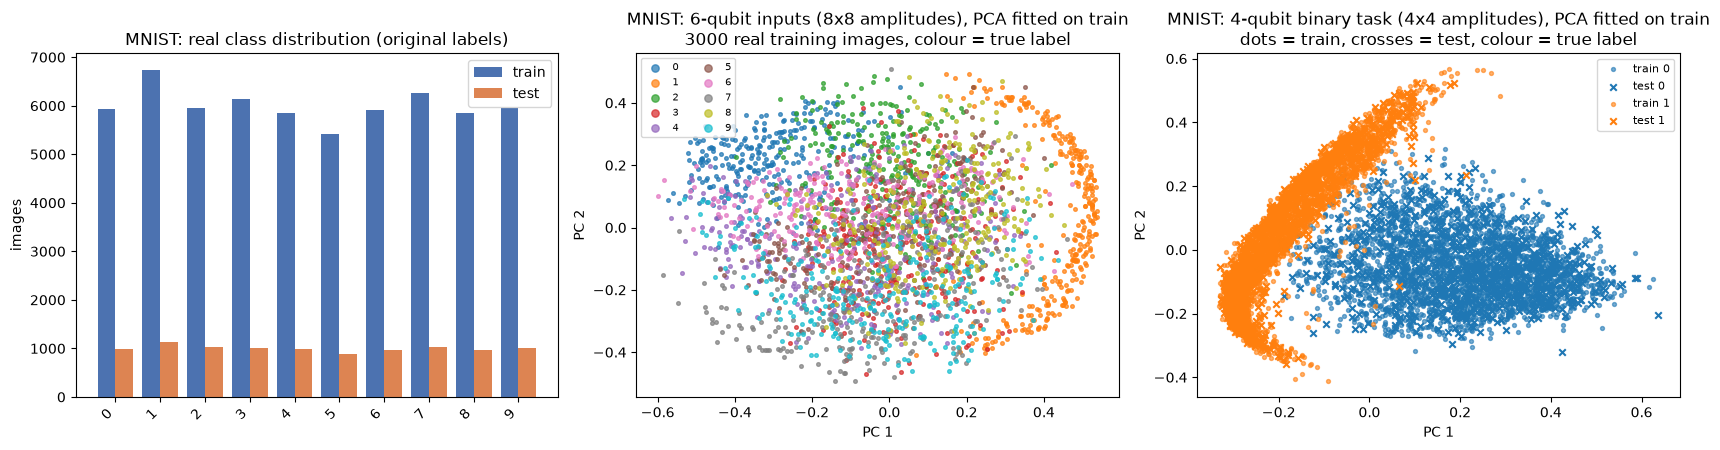

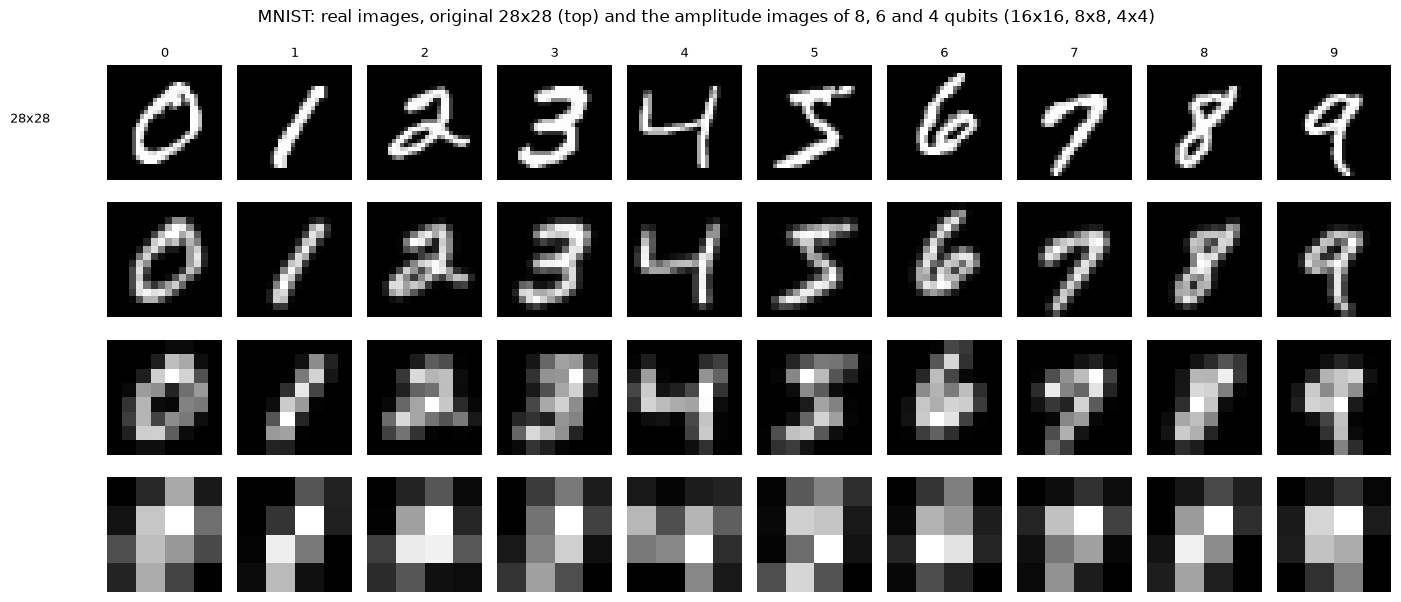

FMNIST: train images (60000, 28, 28) (N, rows, cols), test images (10000, 28, 28)
features: 784 raw pixel intensities pixel_r_c (r, c = 0..27, uint8 0..255); model inputs: 2^n resized, L2-normalised amplitudes
original labels: {0: 'T-shirt', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}
train class counts: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000] | test class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


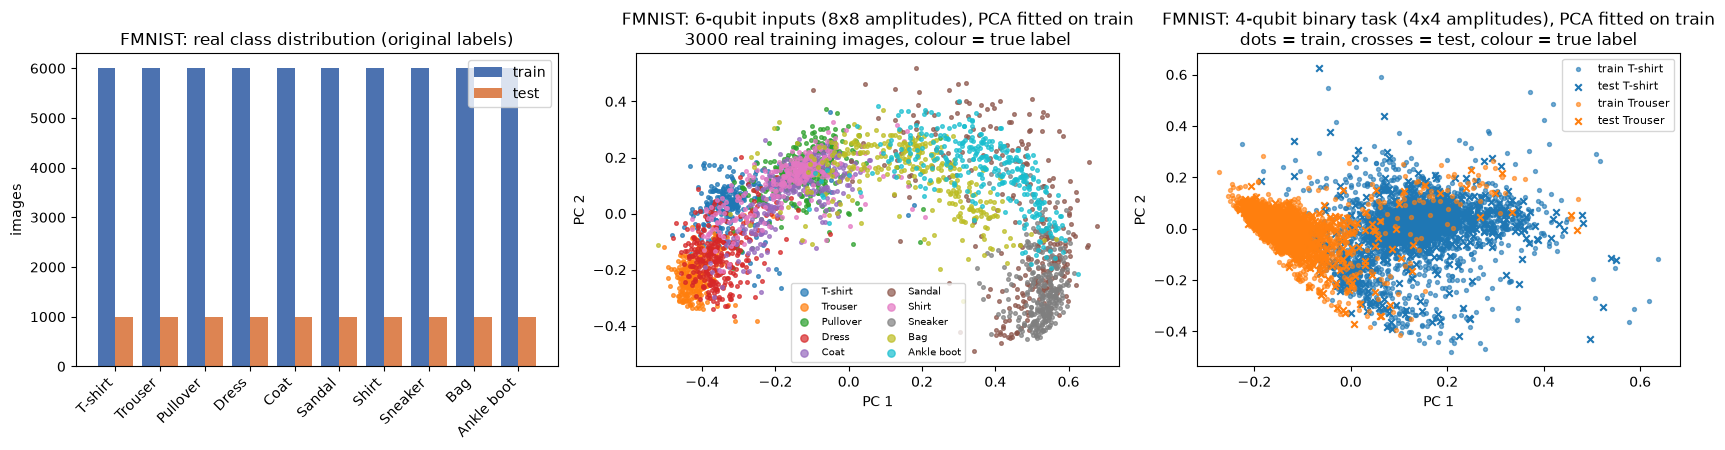

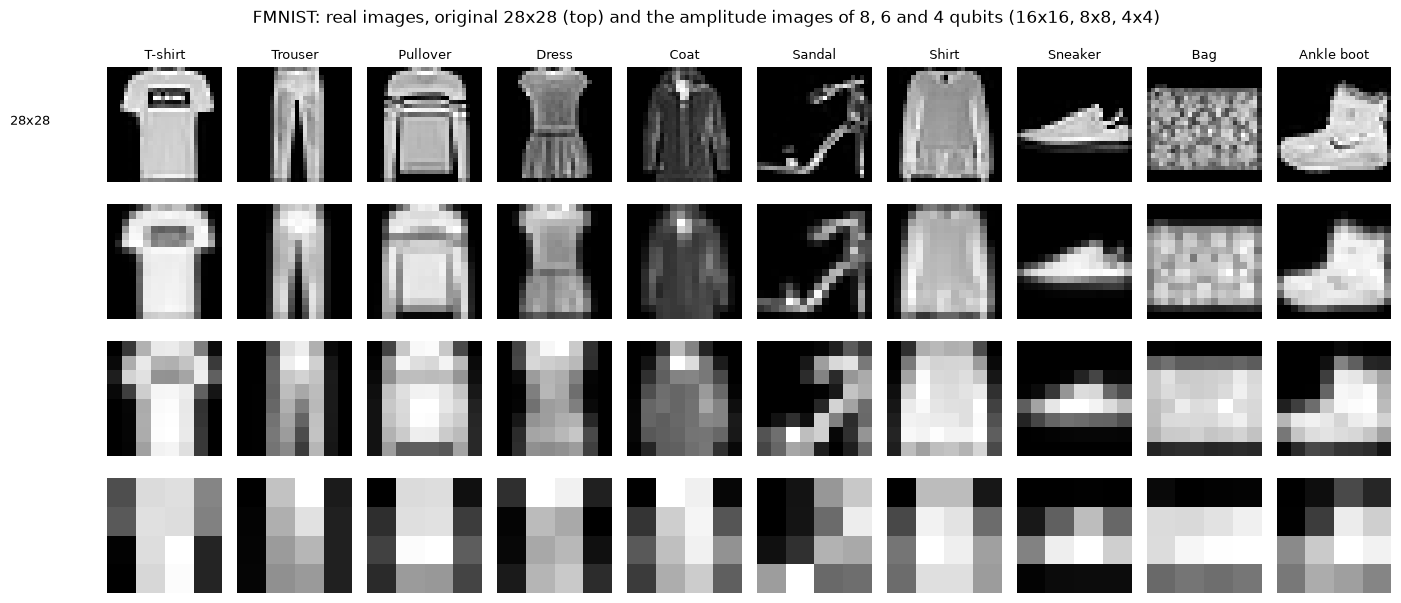

KMNIST: train images (60000, 28, 28) (N, rows, cols), test images (10000, 28, 28)
features: 784 raw pixel intensities pixel_r_c (r, c = 0..27, uint8 0..255); model inputs: 2^n resized, L2-normalised amplitudes
original labels: {0: 'o', 1: 'ki', 2: 'su', 3: 'tsu', 4: 'na', 5: 'ha', 6: 'ma', 7: 'ya', 8: 're', 9: 'wo'}
train class counts: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000] | test class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


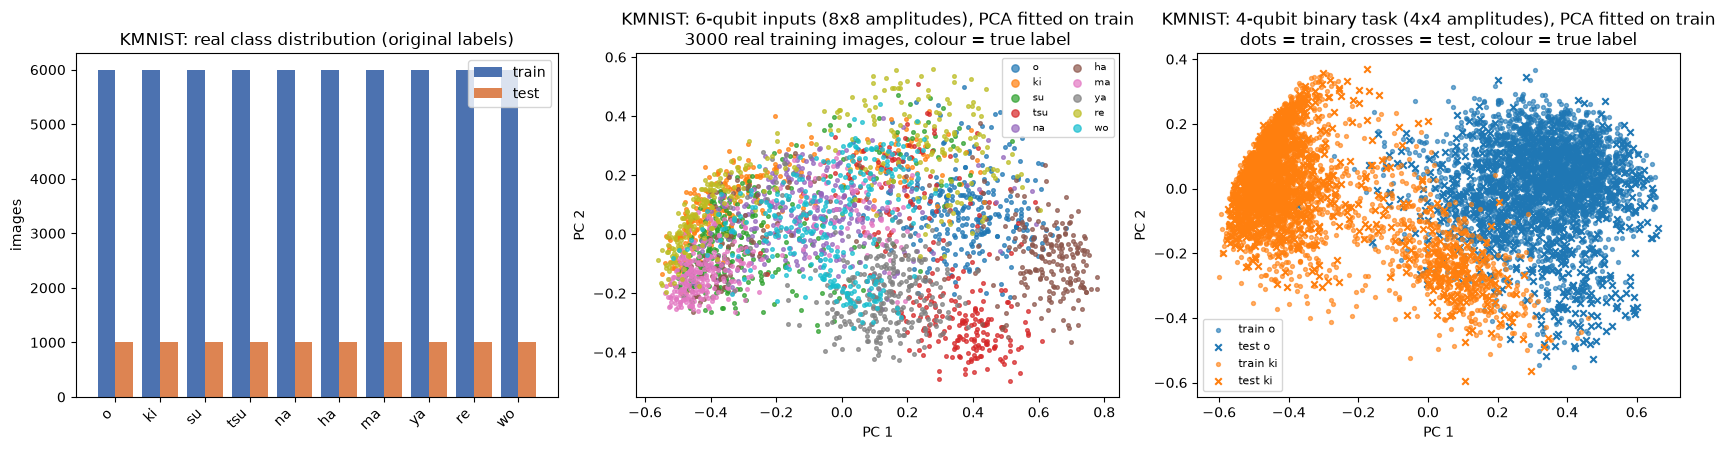

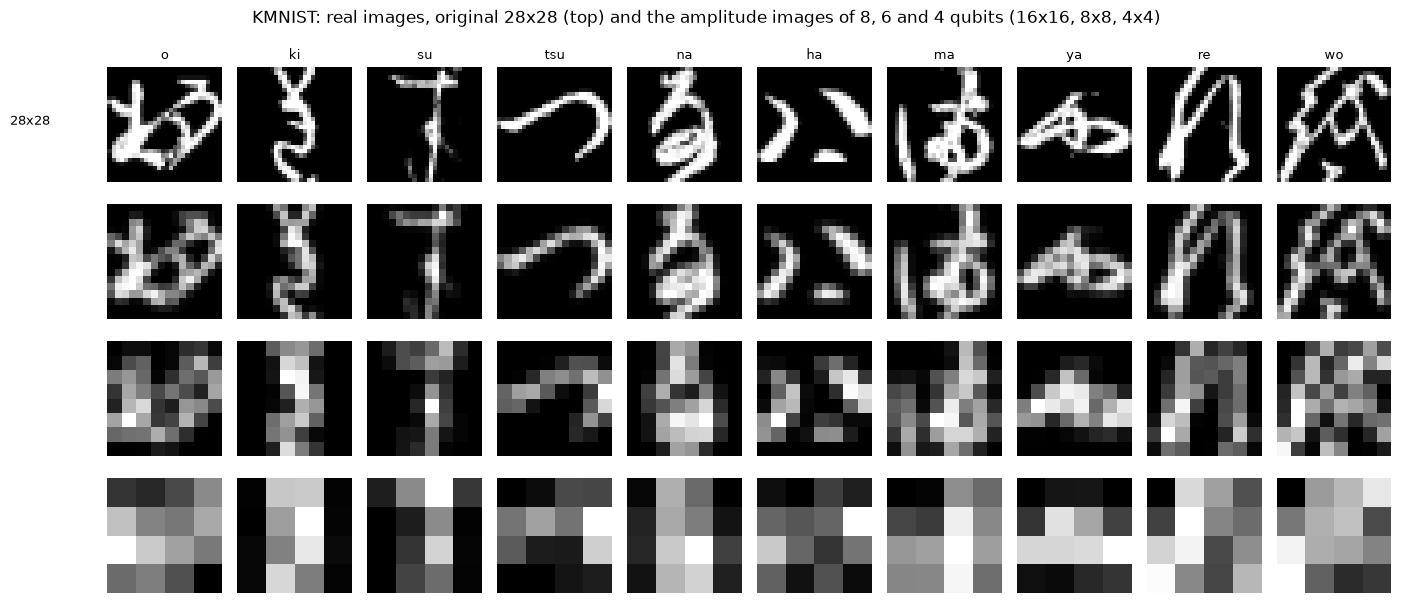

In [6]:
CLASS_NAMES = {
    "MNIST":  [str(i) for i in range(10)],
    "FMNIST": ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
    "KMNIST": ["o", "ki", "su", "tsu", "na", "ha", "ma", "ya", "re", "wo"],
}
cmap10 = plt.get_cmap("tab10")
for ds in DATASETS:
    xtr, ytr, xte, yte = RAW[ds]
    print("=" * 100)
    print(f"{ds}: train images {xtr.shape} (N, rows, cols), test images {xte.shape}")
    print("features: 784 raw pixel intensities pixel_r_c (r, c = 0..27, uint8 0..255); model inputs: 2^n resized, L2-normalised amplitudes")
    print("original labels:", dict(zip(range(10), CLASS_NAMES[ds])))
    print("train class counts:", np.bincount(ytr).tolist(), "| test class counts:", np.bincount(yte).tolist())

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    w = 0.4
    ax[0].bar(np.arange(10) - w / 2, np.bincount(ytr), w, label="train", color="#4c72b0")
    ax[0].bar(np.arange(10) + w / 2, np.bincount(yte), w, label="test", color="#dd8452")
    ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CLASS_NAMES[ds], rotation=45, ha="right")
    ax[0].set_title(f"{ds}: real class distribution (original labels)"); ax[0].set_ylabel("images"); ax[0].legend()

    # PCA of the real 6-qubit model inputs (8 x 8 amplitude vectors), fitted on a training subset, all 10 classes kept
    r = np.random.default_rng(SEED); idx = r.permutation(len(xtr))[:3000]
    A6 = to_amplitudes(xtr[idx], 6).numpy()
    pca = PCA(n_components=2, random_state=SEED).fit(A6)
    P = pca.transform(A6)
    for k in range(10):
        m = ytr[idx] == k
        ax[1].scatter(P[m, 0], P[m, 1], s=7, color=cmap10(k), label=CLASS_NAMES[ds][k], alpha=0.7)
    ax[1].set_title(f"{ds}: 6-qubit inputs (8x8 amplitudes), PCA fitted on train\n3000 real training images, colour = true label")
    ax[1].set_xlabel("PC 1"); ax[1].set_ylabel("PC 2"); ax[1].legend(markerscale=2, fontsize=7, ncol=2)

    # the actual binary 4-qubit task (classes 0 and 1): train (dots) and test (crosses), PCA fitted on the training split
    Xa, ya, Xb, yb = get_split(ds, 4, 2)
    pca4 = PCA(n_components=2, random_state=SEED).fit(Xa.numpy())
    Pa, Pb = pca4.transform(Xa.numpy()), pca4.transform(Xb.numpy())
    for k in range(2):
        ax[2].scatter(Pa[ya.numpy() == k, 0], Pa[ya.numpy() == k, 1], s=8, color=cmap10(k), alpha=0.6, label=f"train {CLASS_NAMES[ds][k]}")
        ax[2].scatter(Pb[yb.numpy() == k, 0], Pb[yb.numpy() == k, 1], s=22, marker="x", color=cmap10(k), label=f"test {CLASS_NAMES[ds][k]}")
    ax[2].set_title(f"{ds}: 4-qubit binary task (4x4 amplitudes), PCA fitted on train\ndots = train, crosses = test, colour = true label")
    ax[2].set_xlabel("PC 1"); ax[2].set_ylabel("PC 2"); ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()

    # real images before / after the resize that feeds the circuit (one image per class)
    fig, ax = plt.subplots(4, 10, figsize=(14, 6.2))
    for k in range(10):
        i = int(np.where(ytr == k)[0][0])
        ax[0, k].imshow(xtr[i], cmap="gray"); ax[0, k].set_title(CLASS_NAMES[ds][k], fontsize=9)
        for row, nq in zip((1, 2, 3), (8, 6, 4)):
            side = 2 ** (nq // 2)
            ax[row, k].imshow(to_amplitudes(xtr[i:i + 1], nq).reshape(side, side).numpy(), cmap="gray")
        for row in range(4):
            ax[row, k].axis("off")
    ax[0, 0].text(-0.5, 0.5, "28x28", transform=ax[0, 0].transAxes, ha="right", fontsize=9)
    fig.suptitle(f"{ds}: real images, original 28x28 (top) and the amplitude images of 8, 6 and 4 qubits (16x16, 8x8, 4x4)")
    plt.tight_layout(); plt.show()

## 2. The model: an exact simulator of the VQC

Every ansatz layer is a *real orthogonal matrix* `K = P . (RY(t_0) x RY(t_1) x ... x RY(t_{n-1}))`: a Kronecker product of the `n` single-qubit rotations followed by the permutation `P` of all the CNOT gates of the layer (a CNOT only swaps amplitudes). Because `RY` and `CNOT` are real, the state vector stays real (the imaginary parts of the paper's complex intervals are identically zero for this ansatz). The output `<Z_i> = P(q_i = 0) - P(q_i = 1) = 2 P(q_i = 0) - 1`, where `P(q_i = 0)` is the sum of the squared amplitudes of all basis states with qubit `i` in `|0>`. Qubit 0 is the most significant bit (PennyLane convention).

The class `Circuit` below contains three things: the exact forward pass (`forward_exact`, `logits`), the **interval** bound propagation (`bounds_interval`) and the **affine** bound propagation (`bounds_affine`). The next section proves the forward pass equal to a real PennyLane QNode.

In [7]:
def entangler_pairs(n):
    """CHOICE: brickwork CNOTs: (0,1),(2,3),... then (1,2),(3,4),..."""
    return [(i, i + 1) for i in range(0, n - 1, 2)] + [(i, i + 1) for i in range(1, n - 1, 2)]

def cnot_layer_perm(n):
    """flat-index permutation p with  new_state = old_state[..., p]  for the whole CNOT layer (qubit 0 = most significant bit)."""
    D = 2 ** n
    idx = np.arange(D)
    # apply the CNOTs sequentially to the basis labels: image of basis state b is f(b); new[f(b)] = old[b]
    f = idx.copy()
    for (c, t) in entangler_pairs(n):
        cb = (f >> (n - 1 - c)) & 1
        f = f ^ (cb << (n - 1 - t))
    inv = np.empty(D, dtype=np.int64); inv[f] = idx   # new[j] = old[inv[j]]
    return torch.tensor(inv)

def ry_matrix(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -s]), torch.stack([s, c])])

class Circuit:
    def __init__(self, n, layers):
        self.n, self.L, self.D = n, layers, 2 ** n
        self.perm = cnot_layer_perm(n)
        self.pairs = entangler_pairs(n)
        idx = torch.arange(self.D)
        self.mask0 = torch.stack([((idx >> (n - 1 - q)) & 1 == 0).to(DTYPE) for q in range(n)])  # (n, D): basis states with qubit q = |0>

    def layer_matrices(self, theta):
        """one real orthogonal D x D matrix per ansatz layer: (RY(t_0) x ... x RY(t_{n-1})) followed by the CNOT permutation."""
        mats = []
        for l in range(self.L):
            K = ry_matrix(theta[l, 0])
            for q in range(1, self.n):
                K = torch.kron(K, ry_matrix(theta[l, q]))
            mats.append(K[self.perm, :])
        return mats

    def forward_exact(self, x, theta, mats=None):
        mats = mats or self.layer_matrices(theta)
        s = x
        for K in mats:
            s = s @ K.T
        return s

    def expz(self, amps, n_out):
        p = amps ** 2
        return 2 * (p @ self.mask0[:n_out].T) - 1      # <Z_q> = P(q=0) - P(q=1) = 2 P(q=0) - 1

    def logits(self, x, theta, n_out):
        return self.expz(self.forward_exact(x, theta), n_out)

    # ---- interval arithmetic: classical IBP through every layer matrix (Eq. 7-8), then |.|^2 (Eq. 9) and 2P-1 (Eq. 10)
    def bounds_interval(self, x, theta, eps, n_out, mats=None):
        mats = mats or self.layer_matrices(theta)
        lo, hi = x - eps, x + eps
        for K in mats:
            Kp, Km = K.clamp(min=0), K.clamp(max=0)
            lo, hi = lo @ Kp.T + hi @ Km.T, hi @ Kp.T + lo @ Km.T
        straddle = (lo < 0) & (hi > 0)
        plo = torch.where(straddle, torch.zeros_like(lo), torch.minimum(lo ** 2, hi ** 2))
        phi = torch.maximum(lo ** 2, hi ** 2)
        m = self.mask0[:n_out].T
        return 2 * (plo @ m) - 1, 2 * (phi @ m) - 1

    # ---- affine arithmetic
    def unitary(self, theta, mats=None):
        mats = mats or self.layer_matrices(theta)
        U = mats[0]
        for K in mats[1:]:
            U = K @ U
        return U

    def bounds_affine(self, x, theta, eps, n_out, mats=None):
        """one noise symbol e_k in [-1,1] per input amplitude (x_k + eps*e_k). Every ansatz layer is linear, so the centre
        and the noise coefficients propagate exactly; only |.|^2 needs the Chebyshev residual (Eq. 20-24)."""
        U = self.unitary(theta, mats)
        c = x @ U.T                                                    # (B, D) centres
        Q = (eps * U.abs().sum(1)) ** 2                                # (D,)   |(sum_k g_jk e_k)^2| <= Q_j
        m = self.mask0[:n_out]                                        # (C, D)
        centre = (c ** 2 + Q / 2) @ m.T                                # (B, C)
        resid = (Q / 2) @ m.T                                          # (C,) Chebyshev residual r
        lin = 2 * eps * torch.einsum("bj,cj,jk->bck", c, m, U)         # (B, C, D) noise coefficients of P(q=0)
        rad = lin.abs().sum(-1) + resid
        return 2 * (centre - rad) - 1, 2 * (centre + rad) - 1


def pgd(circ, theta, x, y, eps, n_out, steps=20, rng=None):
    alpha = 2.5 * eps / steps
    delta = (torch.rand(x.shape, generator=rng, dtype=DTYPE) * 2 - 1) * eps
    for _ in range(steps):
        delta.requires_grad_(True)
        loss = F.cross_entropy(circ.logits(x + delta, theta, n_out), y)
        g, = torch.autograd.grad(loss, delta)
        delta = (delta.detach() + alpha * g.sign()).clamp(-eps, eps)
    return (x + delta).detach()

## Quantum Circuit Architecture

The drawing below is produced by `qml.draw_mpl` from the **real PennyLane QNode** (`default.qubit`) that has exactly the gates of the paper's VQC: `AmplitudeEmbedding` of the image, `L` layers of `RY(theta)` on every qubit followed by the CNOT brick-work, and a Pauli-Z expectation value on each of the first `C` qubits (one per class). A cell then **asserts** that the PyTorch simulator used for training reproduces the QNode output to machine precision on real images, for every distinct (qubits, layers, classes) combination that the experiments below use.

Assumptions where the paper omits circuit details: (i) the CNOT wiring (the paper's Fig. 3 shows "pairs of CNOT gates", the exact pairs cannot be read from the text) is the brick-work `(0,1),(2,3),...` then `(1,2),(3,4),...`; (ii) the logits are the Z-expectations of the **first** `C` qubits; (iii) the amplitude embedding is exact state preparation (on hardware it would be compiled into O(2^n) gates, which is why the paper, like this notebook, simulates it); (iv) there are no noise channels and no shot noise (exact expectation values).

In [8]:
def make_qnode(n, L, C):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch")
    def qnode(amps, theta):
        qml.AmplitudeEmbedding(amps, wires=range(n), normalize=False)      # image -> amplitudes (already L2-normalised)
        for l in range(L):
            for q in range(n):
                qml.RY(theta[l, q], wires=q)                              # trainable rotation
            for (c, t) in entangler_pairs(n):
                qml.CNOT(wires=[c, t])                                    # entanglement (a permutation of amplitudes)
        return [qml.expval(qml.PauliZ(q)) for q in range(C)]             # one logit per class
    return qnode

def run_specs(fast):
    # the experiment grid (also used by the runner below); defined here so that the circuit section knows every architecture
    R = lambda ds, Q, C, L, arith, loss, eps=EPS_DEFAULT, kappa=KAPPA_DEFAULT, seed=0: dict(ds=ds, Q=Q, C=C, L=L, arith=arith, loss=loss, eps=eps, kappa=kappa, seed=seed)
    runs = []
    if fast:
        for arith in ("interval", "affine"):
            runs += [R("MNIST", 4, 2, 2, arith, "margin"), R("MNIST", 4, 2, 2, arith, "ce"), R("MNIST", 4, 4, 2, arith, "margin"),
                     R("FMNIST", 4, 2, 2, arith, "margin"), R("KMNIST", 4, 2, 2, arith, "margin"), R("MNIST", 6, 2, 2, arith, "margin")]
        runs += [R("MNIST", 4, 4, 2, "affine", "ce")]
        runs += [R("MNIST", 4, 2, 2, "affine", "margin", kappa=1.0), R("MNIST", 4, 4, 2, "affine", "margin", kappa=1.0)]       # standard training
        runs += [R("MNIST", 4, 2, 2, "affine", "margin", eps=e) for e in (0.005, 0.010)]                                      # Table III style
        runs += [R("MNIST", 4, 4, 2, "affine", "margin", kappa=k) for k in (0.9, 0.1)]                                         # Table IV style
    else:
        for C in (2, 4):                                                       # Tables I and II, MNIST, 4 qubits
            for L in (2, 8):
                for loss in ("ce", "margin"):
                    for arith in ("interval", "affine"):
                        runs.append(R("MNIST", 4, C, L, arith, loss))
        runs += [R("MNIST", 6, 2, 2, arith, "margin") for arith in ("interval", "affine")]   # 6 qubits (8 and 10 qubits: not run, see table)
        for ds in ("FMNIST", "KMNIST"):
            runs += [R(ds, 4, 2, 2, arith, "margin") for arith in ("interval", "affine")]
        runs += [R("MNIST", 4, 2, 2, "affine", "margin", eps=e) for e in (0.005, 0.010)]
        runs += [R("MNIST", 4, 4, 2, "affine", "margin", eps=e) for e in (0.005, 0.010)]
        runs += [R("MNIST", 4, 4, 2, "affine", "margin", kappa=k) for k in (0.9, 0.1)]
        runs += [R("MNIST", 4, C, 2, "affine", "margin", kappa=1.0) for C in (2, 4)]                              # standard training baseline
        runs += [R("MNIST", 4, 2, 2, "affine", "margin", seed=s) for s in (1, 2)]                                # seed spread
    return runs

RUNS = run_specs(FAST_MODE)
ARCHS = sorted({(r["Q"], r["L"], r["C"]) for r in RUNS})
print(len(RUNS), "models in the grid; distinct (qubits, layers, classes) architectures:", ARCHS)

# 1) the torch simulator used for training equals the QNode on real images, for every architecture
g = torch.Generator().manual_seed(SEED)
for (Q, L, C) in ARCHS:
    th = torch.randn(L, Q, generator=g, dtype=DTYPE)
    A = get_split("MNIST", Q, C)[0][:6]
    qn = make_qnode(Q, L, C)
    ref = torch.stack([torch.stack(qn(A[i], th)) for i in range(len(A))])
    mine = Circuit(Q, L).logits(A, th, C)
    err = (ref - mine).abs().max().item()
    assert err < 1e-10, (Q, L, C, err)
    print(f"qubits={Q} layers={L} classes={C}: max |QNode - simulator| = {err:.2e}  OK")

32 models in the grid; distinct (qubits, layers, classes) architectures: [(4, 2, 2), (4, 2, 4), (4, 8, 2), (4, 8, 4), (6, 2, 2)]
qubits=4 layers=2 classes=2: max |QNode - simulator| = 8.88e-16  OK


qubits=4 layers=2 classes=4: max |QNode - simulator| = 4.44e-16  OK


qubits=4 layers=8 classes=2: max |QNode - simulator| = 1.50e-15  OK


qubits=4 layers=8 classes=4: max |QNode - simulator| = 8.88e-16  OK


qubits=6 layers=2 classes=2: max |QNode - simulator| = 6.66e-16  OK


[4 qubits, 2 layers, readout of 4 qubits]  qubits=4  depth=7  gates={'AmplitudeEmbedding': 1, 'RY': 8, 'CNOT': 6}  trainable parameters=8


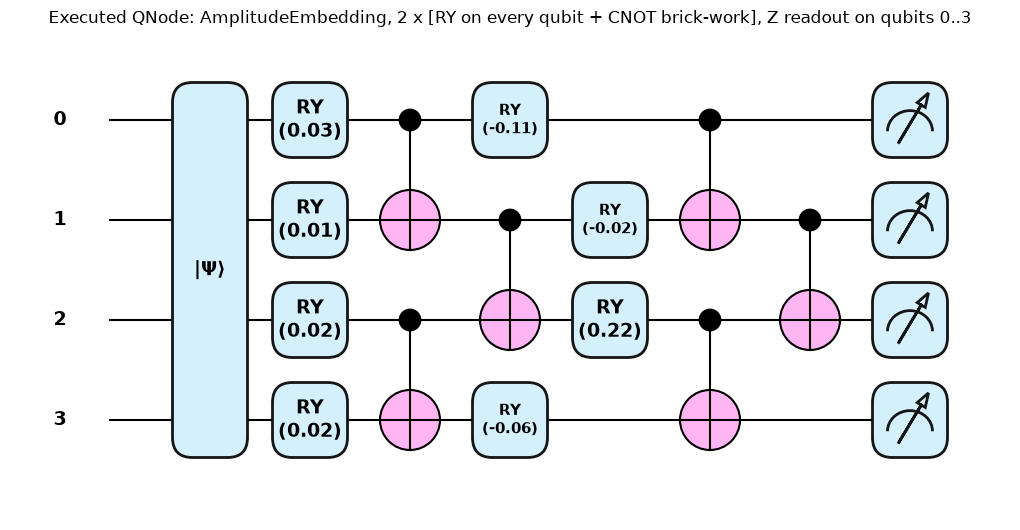

[4 qubits, 8 layers, readout of 4 qubits]  qubits=4  depth=25  gates={'AmplitudeEmbedding': 1, 'RY': 32, 'CNOT': 24}  trainable parameters=32


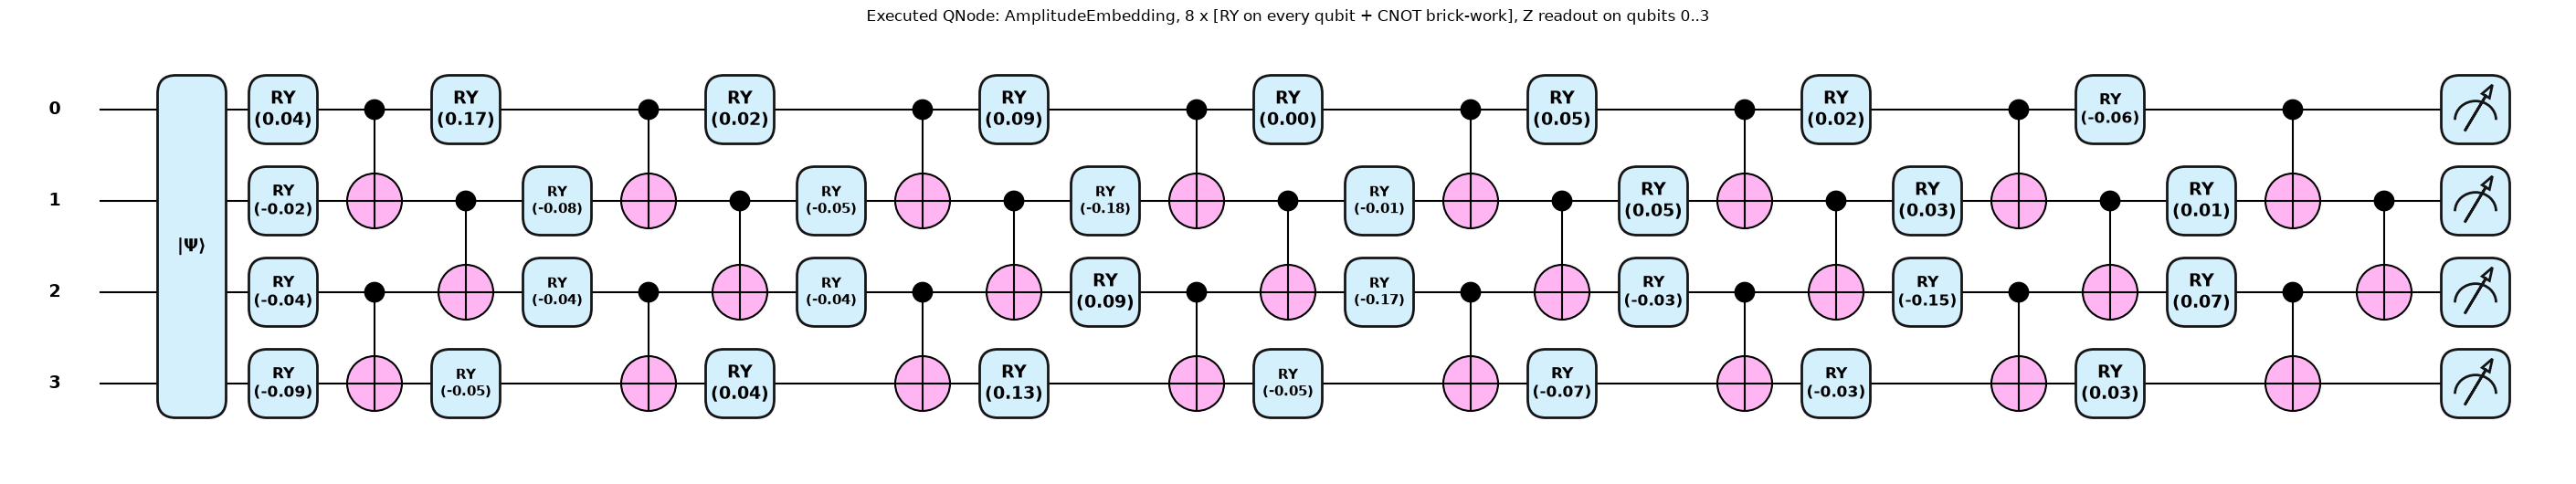

[6 qubits, 2 layers, readout of 2 qubits]  qubits=6  depth=7  gates={'AmplitudeEmbedding': 1, 'RY': 12, 'CNOT': 10}  trainable parameters=12


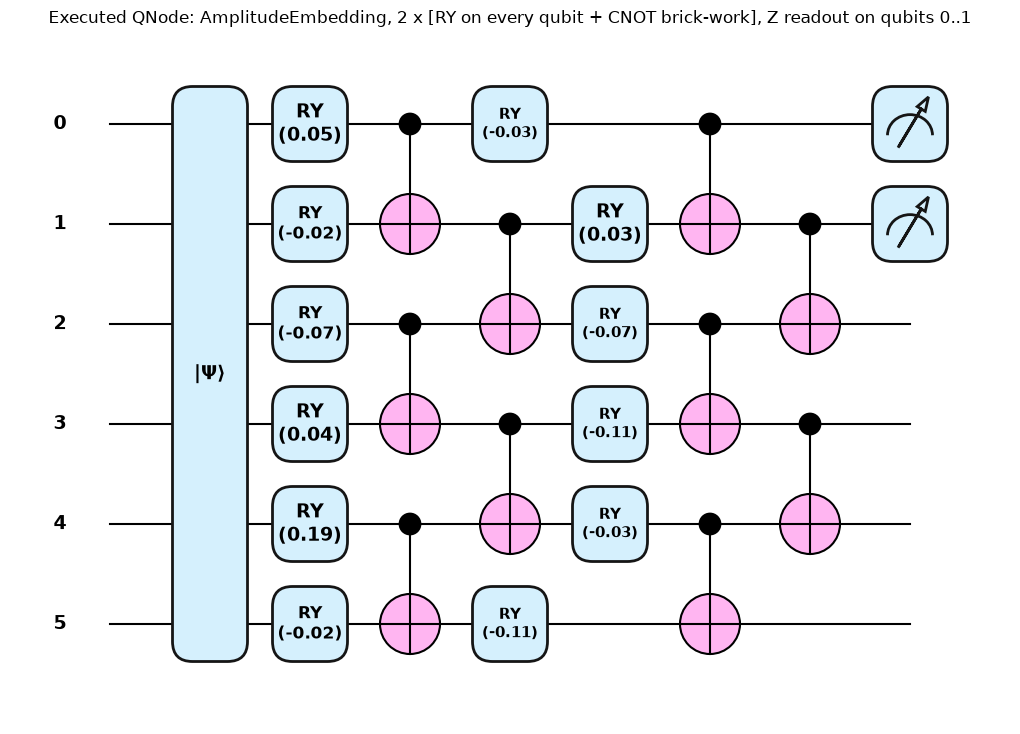

In [9]:
# 2) draw the QNode that is executed (one drawing per distinct (qubits, layers); classes = the largest C used with it)
seen = {}
for (Q, L, C) in ARCHS:
    seen[(Q, L)] = max(seen.get((Q, L), 0), C)
for (Q, L), C in sorted(seen.items()):
    qn = make_qnode(Q, L, C)
    A = get_split("MNIST", Q, C)[0][0]
    th = torch.randn(L, Q, dtype=DTYPE) * 0.1
    specs = qml.specs(qn)(A, th)
    gates = specs.resources.gate_types
    print(f"[{Q} qubits, {L} layers, readout of {C} qubits]  qubits={Q}  depth={specs.resources.depth}  gates={dict(gates)}  trainable parameters={L * Q}")
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(A, th)
    fig.suptitle(f"Executed QNode: AmplitudeEmbedding, {L} x [RY on every qubit + CNOT brick-work], Z readout on qubits 0..{C - 1}", y=1.02)
    plt.show()

## 3. QIBP: propagating the interval through the circuit

`bounds_interval` is the paper's Section III: the input vector becomes the box `[x - eps, x + eps]`; for every layer matrix `K` we use `lower' = K+ lower + K- upper` and `upper' = K+ upper + K- lower` (Eq. 7 and 8); the permutation of the CNOTs just reorders the entries; the probability interval comes from squaring (the lower end is 0 if the interval contains 0), and `<Z_i> = 2 P - 1` (Eq. 9 and 10).

`bounds_affine` is Section IV. Each amplitude is the affine form `x_k + eps e_k` with its own noise symbol `e_k` in [-1, 1]. Since every ansatz layer is linear, the centre and the noise coefficients are mapped *exactly* by the product `U = K_L ... K_1` (no overestimation). The only non-linear step is the square: for amplitude `j`, `a_j = c_j + sum_k g_jk e_k`, so `a_j^2 = c_j^2 + 2 c_j sum_k g_jk e_k + (sum_k g_jk e_k)^2`; the last term is a quantity in `[0, Q_j]` with `Q_j = (sum_k |g_jk|)^2` and is replaced by the Chebyshev centre `Q_j / 2` plus a residual `r_j = Q_j / 2` (Eq. 22). Summing over the amplitudes with qubit `i` in `|0>` keeps the *linear* noise terms correlated and gives the bound `centre +/- (sum_k |noise_k| + r)` (Eq. 24). This correlation is why affine arithmetic is tighter.

Before using the bounds for training, two sanity checks: (a) the **amplitude widths** layer by layer (interval arithmetic widens at every layer, because a layer's matrix is applied to a box that no longer is aligned with its structure: the dependency problem; the affine width is the exact range of the linear map), and (b) **soundness**: random and adversarial perturbations inside the ball must always give logits inside the computed bounds.

interval bounds contain every sampled / attacked logit: True
affine   bounds contain every sampled / attacked logit: True
mean logit-interval width: interval 0.3573 | affine 0.1247 | sampled range 0.1000


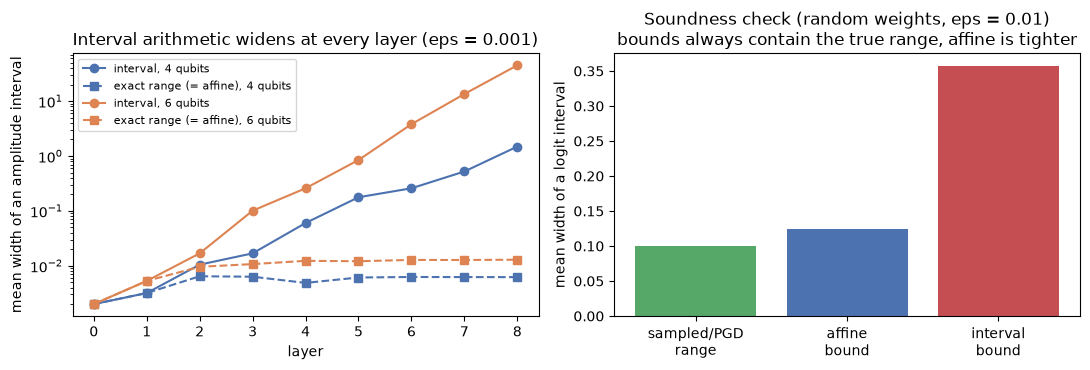

In [10]:
# (a) width of the amplitude intervals after every layer, random weights, one real image per model size
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for Q, col in ((4, "#4c72b0"), (6, "#dd8452")):
    circ = Circuit(Q, 8)
    th = torch.randn(8, Q, dtype=DTYPE, generator=torch.Generator().manual_seed(SEED)) * 1.0
    x = get_split("MNIST", Q, 2)[0][:1]
    eps = 0.001
    mats = circ.layer_matrices(th)
    lo, hi = x - eps, x + eps
    Ucum = torch.eye(circ.D, dtype=DTYPE)
    wi, wa = [float((hi - lo).mean())], [float((hi - lo).mean())]
    for K in mats:
        Kp, Km = K.clamp(min=0), K.clamp(max=0)
        lo, hi = lo @ Kp.T + hi @ Km.T, hi @ Kp.T + lo @ Km.T
        Ucum = K @ Ucum
        wi.append(float((hi - lo).mean())); wa.append(float((2 * eps * Ucum.abs().sum(1)).mean()))
    ax[0].plot(wi, "o-", color=col, label=f"interval, {Q} qubits")
    ax[0].plot(wa, "s--", color=col, label=f"exact range (= affine), {Q} qubits")
ax[0].set_xlabel("layer"); ax[0].set_ylabel("mean width of an amplitude interval"); ax[0].set_yscale("log")
ax[0].set_title("Interval arithmetic widens at every layer (eps = 0.001)"); ax[0].legend(fontsize=8)

# (b) soundness: sampled and PGD-perturbed logits must stay inside both bounds (random weights, eps = 0.01)
Q, L, C, eps = 4, 2, 2, 0.01
circ = Circuit(Q, L); th = torch.randn(L, Q, dtype=DTYPE, generator=torch.Generator().manual_seed(1))
X, y = get_split("MNIST", Q, C)[2][:64], get_split("MNIST", Q, C)[3][:64]
lo_i, hi_i = circ.bounds_interval(X, th, eps, C); lo_a, hi_a = circ.bounds_affine(X, th, eps, C)
wmin = torch.full_like(lo_i, 9.0); wmax = torch.full_like(lo_i, -9.0)
rng = torch.Generator().manual_seed(0)
for _ in range(3000):
    d = (torch.rand(X.shape, generator=rng, dtype=DTYPE) * 2 - 1) * eps
    d = torch.where(torch.rand(X.shape, generator=rng, dtype=DTYPE) < 0.5, d.sign() * eps, d)       # mix of interior points and corners
    z = circ.logits(X + d, th, C); wmin = torch.minimum(wmin, z); wmax = torch.maximum(wmax, z)
xa = pgd(circ, th, X, y, eps, C, 30, rng); z = circ.logits(xa, th, C); wmin = torch.minimum(wmin, z); wmax = torch.maximum(wmax, z)
ok_i = bool(((lo_i <= wmin + 1e-12) & (hi_i >= wmax - 1e-12)).all()); ok_a = bool(((lo_a <= wmin + 1e-12) & (hi_a >= wmax - 1e-12)).all())
print("interval bounds contain every sampled / attacked logit:", ok_i)
print("affine   bounds contain every sampled / attacked logit:", ok_a)
assert ok_i and ok_a
print(f"mean logit-interval width: interval {float((hi_i - lo_i).mean()):.4f} | affine {float((hi_a - lo_a).mean()):.4f} | sampled range {float((wmax - wmin).mean()):.4f}")
ax[1].bar(["sampled/PGD\nrange", "affine\nbound", "interval\nbound"], [float((wmax - wmin).mean()), float((hi_a - lo_a).mean()), float((hi_i - lo_i).mean())], color=["#55a868", "#4c72b0", "#c44e52"])
ax[1].set_ylabel("mean width of a logit interval"); ax[1].set_title("Soundness check (random weights, eps = 0.01)\nbounds always contain the true range, affine is tighter")
plt.tight_layout(); plt.show()

## 4. Certified training, PGD attack and evaluation

* `schedule` implements the paper's `kappa` / `eps` schedule (5 epochs of ordinary training, a 15-epoch linear ramp, constant afterwards; the same fractions are used for any `EPOCHS`).
* `qibp_loss` is Eq. 12: `kappa * CE(z, y) + (1 - kappa) * L_robust`, with `L_robust` the cross entropy on the worst-case logits (`loss="ce"`; lower bound for the true class, upper bounds for the others, Eq. 11) or the margin hinge (`loss="margin"`, Eq. 13 and 14, `gamma = 0.2`). With `kappa = 1` the model is trained in the ordinary way (the **standard-training baseline**; the bounds are then only used to certify).
* `pgd` is the empirical attack: 20 projected-gradient steps inside the `l_inf` ball of radius `eps` around the normalised amplitude vector (the same set that is certified), random start, cross-entropy loss.
* `evaluate` returns the three metrics of the paper: test accuracy (clean), certified accuracy (`lower_y > max_j upper_j`) and PGD accuracy. It also counts *certified samples that PGD fools*: this number must be 0, otherwise the bounds are unsound.

In [11]:
GAMMA = 0.2   # margin target of the paper (also set in the configuration cell)
GAMMA = 0.2

def schedule(epoch, kappa_t, eps_t, epochs):
    """paper: kappa = 1 and eps = 0 for the first 5 of 30 epochs, then a linear ramp over 15 epochs, then constant
    (the same fractions are used when EPOCHS differs from 30)."""
    warm, ramp = 5 * epochs / 30, 15 * epochs / 30
    r = min(1.0, max(0.0, (epoch + 1 - warm) / ramp))
    return 1.0 - (1.0 - kappa_t) * r, eps_t * r

def bounds(circ, x, theta, eps, n_out, arith, mats=None):
    return (circ.bounds_interval if arith == "interval" else circ.bounds_affine)(x, theta, eps, n_out, mats)

def worst_case_logits(lo, hi, y):
    onehot = F.one_hot(y, lo.shape[1]).bool()
    return torch.where(onehot, lo, hi)

def margin_of(lo, hi, y):
    onehot = F.one_hot(y, lo.shape[1]).bool()
    return lo.gather(1, y[:, None])[:, 0] - hi.masked_fill(onehot, -1e9).max(1).values

def qibp_loss(z, lo, hi, y, kappa, loss_type):
    ce = F.cross_entropy(z, y)
    if loss_type == "ce":
        rob = F.cross_entropy(worst_case_logits(lo, hi, y), y)
    else:
        rob = F.relu(GAMMA - margin_of(lo, hi, y)).mean()
    return kappa * ce + (1 - kappa) * rob

@torch.no_grad()
def _eval_core(circ, theta, X, y, eps, n_out, arith):
    mats = circ.layer_matrices(theta)
    z = circ.logits(X, theta, n_out)
    acc = (z.argmax(1) == y).double().mean().item()
    lo, hi = bounds(circ, X, theta, eps, n_out, arith, mats)
    cert = (margin_of(lo, hi, y) > 0)
    return acc, cert, (hi - lo).mean().item()

def evaluate(circ, theta, X, y, eps, n_out, arith, seed=0, pgd_steps=20, bs=500):
    accs, certs, widths, pg = [], [], [], []
    rng = torch.Generator().manual_seed(seed)
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        a, c, w = _eval_core(circ, theta, xb, yb, eps, n_out, arith)
        xa = pgd(circ, theta, xb, yb, eps, n_out, pgd_steps, rng)
        with torch.no_grad():
            pr = (circ.logits(xa, theta, n_out).argmax(1) == yb)
        accs.append(a * len(xb)); certs.append(c); widths.append(w * len(xb)); pg.append(pr)
    cert = torch.cat(certs); pg = torch.cat(pg)
    N = len(X)
    return dict(test_acc=100 * sum(accs) / N, cert_acc=100 * cert.double().mean().item(), pgd_acc=100 * pg.double().mean().item(),
                width=sum(widths) / N, cert_but_fooled=int((cert & ~pg).sum().item()))

def train_qibp(Xtr, ytr, Xte, yte, n, C, L, arith, loss_type, eps_t, kappa_t, epochs, batch, seed, lr=0.005, wd=0.01, pgd_steps=20, log=None):
    circ = Circuit(n, L)
    g = torch.Generator().manual_seed(seed)
    theta = (torch.randn(L, n, generator=g, dtype=DTYPE)).requires_grad_(True)  # CHOICE: init N(0, 1)
    opt = torch.optim.Adam([theta], lr=lr, weight_decay=wd)
    N = len(Xtr); hist = []
    t0 = time.time()
    for ep in range(epochs):
        kappa, eps = schedule(ep, kappa_t, eps_t, epochs)
        perm = torch.randperm(N, generator=g)
        tot = 0.0
        for i in range(0, N, batch):
            idx = perm[i:i + batch]
            xb, yb = Xtr[idx], ytr[idx]
            mats = circ.layer_matrices(theta)
            z = circ.expz(circ.forward_exact(xb, theta, mats), C)
            if kappa < 1.0 and eps > 0:
                lo, hi = bounds(circ, xb, theta, eps, C, arith, mats)
                loss = qibp_loss(z, lo, hi, yb, kappa, loss_type)
            else:
                loss = F.cross_entropy(z, yb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        hist.append(tot / N)
        if log: log(ep, hist[-1], kappa, eps)
    train_time = time.time() - t0
    th = theta.detach()
    res = evaluate(circ, th, Xte, yte, eps_t, C, arith, seed=seed, pgd_steps=pgd_steps)
    res.update(train_time=train_time, loss_hist=hist)
    return th, res

## 5. The experiments

The runner trains every model of the grid defined in `run_specs` (a reduced version of the paper's Tables I to IV, see the table of choices) and stores the three metrics. Each finished model is cached in `RESULTS_FILE`, so an interrupted run resumes where it stopped. The grid in this execution:

* **Tables I and II**: MNIST with 4 qubits (2 and 4 classes, 2 and 8 layers, cross-entropy and margin loss, interval and affine arithmetic), plus 6 qubits (2 classes, 2 layers) and FMNIST / KMNIST with 4 qubits (2 classes, 2 layers, margin loss); `eps = 0.001`, `kappa = 0.5`.
* **Table III**: `eps` in {0.001, 0.005, 0.010} with affine arithmetic and margin loss.
* **Table IV**: `kappa` in {0.9, 0.5, 0.1}.
* **Extras not in the paper**: standard training (`kappa = 1`) certified with the same bounds, three seeds of one configuration, and classical baselines.

Not run in this execution (CPU budget): 8- and 10-qubit models, 6-class models, 8-layer models for 6 qubits, and the 4-class and 8-layer rows for FMNIST / KMNIST; the paper's numbers for them are therefore not checked.

The paper's own training set is the full data set and 30 epochs on GPUs; the budgets used here are in the configuration cell.

In [12]:
PAPER_TIMING = {}
def spec_key(s):
    return f"{s['ds']}|Q{s['Q']}|C{s['C']}|L{s['L']}|{s['arith']}|{s['loss']}|e{s['eps']}|k{s['kappa']}|s{s['seed']}"

CACHE = json.load(open(RESULTS_FILE)) if os.path.exists(RESULTS_FILE) else {}
THETAS = {}

def run_one(s):
    key = spec_key(s)
    if key in CACHE:
        return CACHE[key]
    Xtr, ytr, Xte, yte = get_split(s["ds"], s["Q"], s["C"])
    th, res = train_qibp(Xtr, ytr, Xte, yte, s["Q"], s["C"], s["L"], s["arith"], s["loss"], s["eps"], s["kappa"],
                         EPOCHS, BATCH, SEED + s["seed"], lr=LR, wd=WEIGHT_DECAY, pgd_steps=PGD_STEPS)
    rec = dict(s); rec.update({k: v for k, v in res.items() if k != "loss_hist"})
    rec["final_loss"] = res["loss_hist"][-1]; rec["loss_hist"] = [round(v, 5) for v in res["loss_hist"]]
    rec["theta"] = th.tolist()
    CACHE[key] = rec
    json.dump(CACHE, open(RESULTS_FILE, "w"))
    return rec

for i, s in enumerate(RUNS):
    t = time.time(); r = run_one(s)
    tag = "standard" if s["kappa"] == 1.0 else s["loss"]
    print(f"[{i + 1:2d}/{len(RUNS)}] {s['ds']:6s} Q={s['Q']} C={s['C']} L={s['L']} {s['arith']:8s} {tag:8s} eps={s['eps']} kappa={s['kappa']} seed={s['seed']}"
          f" | test {r['test_acc']:5.1f}  cert {r['cert_acc']:5.1f}  PGD {r['pgd_acc']:5.1f} | train {r['train_time']:6.1f}s | total {time.time() - T0:6.0f}s")
    THETAS[spec_key(s)] = torch.tensor(r["theta"], dtype=DTYPE)

df = pd.DataFrame([CACHE[spec_key(s)] for s in RUNS]).drop(columns=["theta", "loss_hist"])
df["training"] = np.where(df["kappa"] == 1.0, "standard", "QIBP-" + df["arith"])
assert (df["cert_but_fooled"] == 0).all(), "a certified sample was fooled by PGD: the bounds would be unsound"
print("\nSoundness over all", len(df), "models: samples certified but fooled by PGD =", int(df["cert_but_fooled"].sum()))

[ 1/32] MNIST  Q=4 C=2 L=2 interval ce       eps=0.001 kappa=0.5 seed=0 | test  83.9  cert  78.1  PGD  83.5 | train   57.6s | total     49s
[ 2/32] MNIST  Q=4 C=2 L=2 affine   ce       eps=0.001 kappa=0.5 seed=0 | test  83.9  cert  82.5  PGD  83.5 | train   36.1s | total     49s
[ 3/32] MNIST  Q=4 C=2 L=2 interval margin   eps=0.001 kappa=0.5 seed=0 | test  88.5  cert  81.9  PGD  87.9 | train   35.9s | total     49s
[ 4/32] MNIST  Q=4 C=2 L=2 affine   margin   eps=0.001 kappa=0.5 seed=0 | test  90.8  cert  89.4  PGD  90.2 | train   32.6s | total     49s
[ 5/32] MNIST  Q=4 C=2 L=8 interval ce       eps=0.001 kappa=0.5 seed=0 | test  94.4  cert  92.0  PGD  94.3 | train  135.9s | total     49s
[ 6/32] MNIST  Q=4 C=2 L=8 affine   ce       eps=0.001 kappa=0.5 seed=0 | test  95.5  cert  95.1  PGD  95.2 | train  104.1s | total     49s
[ 7/32] MNIST  Q=4 C=2 L=8 interval margin   eps=0.001 kappa=0.5 seed=0 | test  97.3  cert  93.2  PGD  97.1 | train  115.3s | total     49s
[ 8/32] MNIST  Q=4 C

In [13]:
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
show = df[["ds", "Q", "C", "L", "training", "loss", "eps", "kappa", "seed", "test_acc", "cert_acc", "pgd_acc", "train_time"]].copy()
show[["test_acc", "cert_acc", "pgd_acc", "train_time"]] = show[["test_acc", "cert_acc", "pgd_acc", "train_time"]].round(2)
print(f"All {len(show)} trained models (accuracies in %, N_TEST={N_TEST} test images each)")
show

All 32 trained models (accuracies in %, N_TEST=1500 test images each)


,ds,Q,C,L,training,loss,eps,kappa,seed,test_acc,cert_acc,pgd_acc,train_time
0,MNIST,4,2,2,QIBP-interval,ce,0.001,0.5,0,83.93,78.07,83.47,57.60
1,MNIST,4,2,2,QIBP-affine,ce,0.001,0.5,0,83.87,82.47,83.47,36.13
2,MNIST,4,2,2,QIBP-interval,margin,0.001,0.5,0,88.47,81.93,87.87,35.88
3,MNIST,4,2,2,QIBP-affine,margin,0.001,0.5,0,90.80,89.40,90.20,32.64
4,MNIST,4,2,8,QIBP-interval,ce,0.001,0.5,0,94.40,92.00,94.27,135.87
5,MNIST,4,2,8,QIBP-affine,ce,0.001,0.5,0,95.53,95.07,95.20,104.08
6,MNIST,4,2,8,QIBP-interval,margin,0.001,0.5,0,97.27,93.20,97.07,115.31
7,MNIST,4,2,8,QIBP-affine,margin,0.001,0.5,0,97.80,97.67,97.73,140.66
8,MNIST,4,4,2,QIBP-interval,ce,0.001,0.5,0,37.80,27.60,36.53,75.43
9,MNIST,4,4,2,QIBP-affine,ce,0.001,0.5,0,31.60,29.40,30.40,73.36


## 6. Side-by-side with the paper

The paper's numbers (Tables I to IV) were read from the PDF text. Tables I and II (`eps = 0.001`, `kappa = 0.5`) are keyed by arithmetic, data set, qubits, classes, layers and loss. A verdict is *reproduced* if the notebook is within **2 accuracy points** of the paper, *exceeded* if it is more than 2 points higher and *not reached* if it is more than 2 points lower. The training sets here are 2.5 to 25 times smaller than the paper's and trained for fewer steps, so a gap that grows with the model size is expected and is reported as it is.

In [14]:
# Paper values: {"<arithmetic>|<dataset>|<qubits>|<classes>|<layers>|<loss>": [test acc, certified acc, PGD acc]} (Tables I and II)
PAPER_T12 = json.loads('{"affine|FMNIST|10|10|2|ce":[20.4,0.66,19.9],"affine|FMNIST|10|10|2|margin":[11.15,0.0,6.69],"affine|FMNIST|10|10|8|ce":[11.47,0.64,11.06],"affine|FMNIST|10|10|8|margin":[23.99,6.65,21.06],"affine|FMNIST|10|2|2|ce":[90.15,67.55,89.75],"affine|FMNIST|10|2|2|margin":[89.55,72.35,89.3],"affine|FMNIST|10|2|8|ce":[94.75,91.25,94.5],"affine|FMNIST|10|2|8|margin":[94.7,91.05,94.65],"affine|FMNIST|4|2|2|ce":[92.15,91.6,91.9],"affine|FMNIST|4|2|2|margin":[92.6,92.15,92.35],"affine|FMNIST|4|2|8|ce":[94.65,94.1,94.45],"affine|FMNIST|4|2|8|margin":[94.65,94.15,94.4],"affine|FMNIST|4|4|2|ce":[55.68,54.68,55.45],"affine|FMNIST|4|4|2|margin":[63.43,58.23,62.3],"affine|FMNIST|4|4|8|ce":[82.43,80.25,82.03],"affine|FMNIST|4|4|8|margin":[83.55,82.03,83.08],"affine|FMNIST|6|2|2|ce":[92.1,91.35,91.8],"affine|FMNIST|6|2|2|margin":[92.5,91.15,92.15],"affine|FMNIST|6|2|8|ce":[93.45,92.4,93.2],"affine|FMNIST|6|2|8|margin":[93.6,92.8,93.3],"affine|FMNIST|6|6|2|ce":[27.57,22.43,26.83],"affine|FMNIST|6|6|2|margin":[48.52,29.98,46.58],"affine|FMNIST|6|6|8|ce":[72.62,58.9,71.4],"affine|FMNIST|6|6|8|margin":[71.2,61.13,70.38],"affine|FMNIST|8|2|2|ce":[71.9,54.4,70.8],"affine|FMNIST|8|2|2|margin":[93.35,89.55,93.3],"affine|FMNIST|8|2|8|ce":[94.65,93.55,94.5],"affine|FMNIST|8|2|8|margin":[94.85,93.8,94.85],"affine|FMNIST|8|8|2|ce":[27.13,0.86,26.26],"affine|FMNIST|8|8|2|margin":[30.16,12.14,28.01],"affine|FMNIST|8|8|8|ce":[47.85,17.3,46.74],"affine|FMNIST|8|8|8|margin":[58.86,30.46,56.88],"affine|KMNIST|10|10|2|ce":[10.83,0.2,9.03],"affine|KMNIST|10|10|2|margin":[10.82,0.2,9.02],"affine|KMNIST|10|10|8|ce":[11.05,1.19,10.71],"affine|KMNIST|10|10|8|margin":[10.43,0.96,9.19],"affine|KMNIST|10|2|2|ce":[83.6,67.15,83.05],"affine|KMNIST|10|2|2|margin":[83.7,67.2,83.0],"affine|KMNIST|10|2|8|ce":[87.95,74.45,87.7],"affine|KMNIST|10|2|8|margin":[89.6,75.25,89.25],"affine|KMNIST|4|2|2|ce":[92.6,92.3,92.45],"affine|KMNIST|4|2|2|margin":[93.1,92.6,92.75],"affine|KMNIST|4|2|8|ce":[93.85,93.65,93.65],"affine|KMNIST|4|2|8|margin":[96.15,95.6,95.85],"affine|KMNIST|4|4|2|ce":[54.53,51.93,53.3],"affine|KMNIST|4|4|2|margin":[55.68,52.78,54.53],"affine|KMNIST|4|4|8|ce":[71.18,69.25,70.35],"affine|KMNIST|4|4|8|margin":[71.35,69.4,70.55],"affine|KMNIST|6|2|2|ce":[93.3,91.7,93.0],"affine|KMNIST|6|2|2|margin":[93.45,91.8,93.0],"affine|KMNIST|6|2|8|ce":[94.75,93.8,94.65],"affine|KMNIST|6|2|8|margin":[96.5,95.6,96.3],"affine|KMNIST|6|6|2|ce":[33.3,27.57,32.52],"affine|KMNIST|6|6|2|margin":[37.4,29.92,36.15],"affine|KMNIST|6|6|8|ce":[52.0,45.88,50.93],"affine|KMNIST|6|6|8|margin":[59.17,52.6,58.22],"affine|KMNIST|8|2|2|ce":[89.05,85.2,88.7],"affine|KMNIST|8|2|2|margin":[91.0,85.85,90.35],"affine|KMNIST|8|2|8|ce":[92.35,89.65,92.0],"affine|KMNIST|8|2|8|margin":[95.15,90.3,95.0],"affine|KMNIST|8|8|2|ce":[22.26,7.98,21.23],"affine|KMNIST|8|8|2|margin":[19.06,5.89,17.29],"affine|KMNIST|8|8|8|ce":[33.55,14.08,32.4],"affine|KMNIST|8|8|8|margin":[37.81,14.58,32.4],"affine|MNIST|10|10|2|ce":[20.96,6.25,20.48],"affine|MNIST|10|10|2|margin":[10.57,0.41,8.95],"affine|MNIST|10|10|8|ce":[20.82,13.83,20.49],"affine|MNIST|10|10|8|margin":[10.84,1.5,9.67],"affine|MNIST|10|2|2|ce":[98.2,88.13,98.11],"affine|MNIST|10|2|2|margin":[99.29,93.29,99.24],"affine|MNIST|10|2|8|ce":[98.11,92.34,97.92],"affine|MNIST|10|2|8|margin":[99.24,93.57,99.1],"affine|MNIST|4|2|2|ce":[92.34,91.54,91.63],"affine|MNIST|4|2|2|margin":[96.5,96.17,96.22],"affine|MNIST|4|2|8|ce":[94.61,94.42,94.52],"affine|MNIST|4|2|8|margin":[97.12,96.69,96.83],"affine|MNIST|4|4|2|ce":[47.27,44.05,46.09],"affine|MNIST|4|4|2|margin":[70.72,65.67,68.44],"affine|MNIST|4|4|8|ce":[80.92,79.5,79.94],"affine|MNIST|4|4|8|margin":[87.49,86.24,86.72],"affine|MNIST|6|2|2|ce":[98.77,98.2,98.68],"affine|MNIST|6|2|2|margin":[99.24,99.05,99.24],"affine|MNIST|6|2|8|ce":[99.57,99.53,99.57],"affine|MNIST|6|2|8|margin":[99.67,99.53,99.62],"affine|MNIST|6|6|2|ce":[45.53,40.28,44.47],"affine|MNIST|6|6|2|margin":[51.07,40.47,48.86],"affine|MNIST|6|6|8|ce":[72.11,67.63,71.27],"affine|MNIST|6|6|8|margin":[82.47,77.76,81.79],"affine|MNIST|8|2|2|ce":[96.83,94.18,96.64],"affine|MNIST|8|2|2|margin":[98.77,97.68,98.68],"affine|MNIST|8|2|8|ce":[99.67,99.43,99.67],"affine|MNIST|8|2|8|margin":[99.76,99.43,99.76],"affine|MNIST|8|8|2|ce":[27.48,17.15,26.89],"affine|MNIST|8|8|2|margin":[31.36,17.33,30.29],"affine|MNIST|8|8|8|ce":[57.35,42.56,56.53],"affine|MNIST|8|8|8|margin":[62.19,43.78,61.19],"interval|FMNIST|10|10|2|ce":[19.95,0.7,19.26],"interval|FMNIST|10|10|2|margin":[11.25,0.0,6.8],"interval|FMNIST|10|10|8|ce":[9.9,0.0,7.69],"interval|FMNIST|10|10|8|margin":[13.84,0.03,9.62],"interval|FMNIST|10|2|2|ce":[74.5,37.15,73.7],"interval|FMNIST|10|2|2|margin":[83.4,43.15,82.95],"interval|FMNIST|10|2|8|ce":[58.9,46.85,58.2],"interval|FMNIST|10|2|8|margin":[93.1,70.25,92.95],"interval|FMNIST|4|2|2|ce":[91.95,89.2,91.85],"interval|FMNIST|4|2|2|margin":[92.45,89.7,92.3],"interval|FMNIST|4|2|8|ce":[94.7,93.25,94.2],"interval|FMNIST|4|2|8|margin":[94.45,92.85,94.3],"interval|FMNIST|4|4|2|ce":[55.0,53.4,54.75],"interval|FMNIST|4|4|2|margin":[56.08,51.15,55.6],"interval|FMNIST|4|4|8|ce":[82.83,69.33,82.28],"interval|FMNIST|4|4|8|margin":[82.97,74.53,82.47],"interval|FMNIST|6|2|2|ce":[91.85,89.2,91.55],"interval|FMNIST|6|2|2|margin":[92.45,88.8,92.15],"interval|FMNIST|6|2|8|ce":[92.5,87.5,92.3],"interval|FMNIST|6|2|8|margin":[93.5,89.15,93.3],"interval|FMNIST|6|6|2|ce":[26.7,15.95,26.2],"interval|FMNIST|6|6|2|margin":[41.53,14.63,40.3],"interval|FMNIST|6|6|8|ce":[45.83,40.17,45.45],"interval|FMNIST|6|6|8|margin":[57.92,39.97,56.98],"interval|FMNIST|8|2|2|ce":[51.85,49.55,51.6],"interval|FMNIST|8|2|2|margin":[91.75,74.9,91.55],"interval|FMNIST|8|2|8|ce":[93.85,85.85,93.8],"interval|FMNIST|8|2|8|margin":[94.35,87.05,94.2],"interval|FMNIST|8|8|2|ce":[24.41,5.31,24.23],"interval|FMNIST|8|8|2|margin":[21.82,11.56,19.2],"interval|FMNIST|8|8|8|ce":[27.48,19.06,27.09],"interval|FMNIST|8|8|8|margin":[28.84,15.14,27.9],"interval|KMNIST|10|10|2|ce":[10.79,0.21,9.0],"interval|KMNIST|10|10|2|margin":[10.78,0.2,8.99],"interval|KMNIST|10|10|8|ce":[9.93,0.96,8.83],"interval|KMNIST|10|10|8|margin":[9.89,0.94,8.86],"interval|KMNIST|10|2|2|ce":[74.5,48.5,73.7],"interval|KMNIST|10|2|2|margin":[76.9,48.3,75.9],"interval|KMNIST|10|2|8|ce":[85.7,39.6,85.45],"interval|KMNIST|10|2|8|margin":[85.2,43.15,84.9],"interval|KMNIST|4|2|2|ce":[92.8,91.45,92.65],"interval|KMNIST|4|2|2|margin":[92.95,91.65,92.8],"interval|KMNIST|4|2|8|ce":[94.4,91.9,94.3],"interval|KMNIST|4|2|8|margin":[95.8,92.9,95.7],"interval|KMNIST|4|4|2|ce":[56.95,50.45,56.02],"interval|KMNIST|4|4|2|margin":[57.05,49.12,55.83],"interval|KMNIST|4|4|8|ce":[64.75,45.2,63.75],"interval|KMNIST|4|4|8|margin":[69.12,47.67,68.38],"interval|KMNIST|6|2|2|ce":[92.1,84.7,91.6],"interval|KMNIST|6|2|2|margin":[93.1,83.8,92.75],"interval|KMNIST|6|2|8|ce":[92.25,86.65,92.1],"interval|KMNIST|6|2|8|margin":[94.05,85.65,93.75],"interval|KMNIST|6|6|2|ce":[30.82,20.52,30.03],"interval|KMNIST|6|6|2|margin":[34.03,22.78,33.2],"interval|KMNIST|6|6|8|ce":[38.3,13.08,37.42],"interval|KMNIST|6|6|8|margin":[38.7,13.77,37.75],"interval|KMNIST|8|2|2|ce":[87.95,66.5,87.7],"interval|KMNIST|8|2|2|margin":[90.25,68.75,89.95],"interval|KMNIST|8|2|8|ce":[91.65,80.25,91.35],"interval|KMNIST|8|2|8|margin":[91.0,35.3,90.45],"interval|KMNIST|8|8|2|ce":[15.57,5.99,14.82],"interval|KMNIST|8|8|2|margin":[14.36,3.65,13.44],"interval|KMNIST|8|8|8|ce":[22.06,13.18,21.43],"interval|KMNIST|8|8|8|margin":[18.86,6.21,17.95],"interval|MNIST|10|10|2|ce":[10.41,0.41,8.92],"interval|MNIST|10|10|2|margin":[10.38,0.42,8.92],"interval|MNIST|10|10|8|ce":[8.93,1.68,8.15],"interval|MNIST|10|10|8|margin":[8.95,1.55,8.06],"interval|MNIST|10|2|2|ce":[96.88,55.65,96.74],"interval|MNIST|10|2|2|margin":[98.01,58.3,97.87],"interval|MNIST|10|2|8|ce":[97.73,67.75,97.59],"interval|MNIST|10|2|8|margin":[98.01,80.99,97.78],"interval|MNIST|4|2|2|ce":[92.48,90.5,92.1],"interval|MNIST|4|2|2|margin":[96.36,95.37,96.12],"interval|MNIST|4|2|8|ce":[94.0,92.01,93.81],"interval|MNIST|4|2|8|margin":[97.07,94.37,96.78],"interval|MNIST|4|4|2|ce":[45.3,38.06,44.07],"interval|MNIST|4|4|2|margin":[66.63,51.89,64.57],"interval|MNIST|4|4|8|ce":[75.58,65.19,74.62],"interval|MNIST|4|4|8|margin":[82.73,72.17,81.72],"interval|MNIST|6|2|2|ce":[98.58,97.92,98.49],"interval|MNIST|6|2|2|margin":[99.24,98.58,99.2],"interval|MNIST|6|2|8|ce":[98.96,97.59,98.91],"interval|MNIST|6|2|8|margin":[99.57,98.11,99.57],"interval|MNIST|6|6|2|ce":[41.2,30.58,39.83],"interval|MNIST|6|6|2|margin":[44.79,29.25,42.65],"interval|MNIST|6|6|8|ce":[44.35,29.53,43.72],"interval|MNIST|6|6|8|margin":[59.01,34.22,58.23],"interval|MNIST|8|2|2|ce":[95.37,87.19,95.04],"interval|MNIST|8|2|2|margin":[98.11,95.22,97.97],"interval|MNIST|8|2|8|ce":[96.74,79.72,96.5],"interval|MNIST|8|2|8|margin":[99.48,69.46,99.43],"interval|MNIST|8|8|2|ce":[27.53,13.68,26.79],"interval|MNIST|8|8|2|margin":[27.23,12.71,26.51],"interval|MNIST|8|8|8|ce":[26.82,9.54,25.89],"interval|MNIST|8|8|8|margin":[24.59,8.03,23.31]}')
# Table III (affine, margin, kappa = 0.5): (qubits, classes, layers, eps) -> (test acc, certified acc)
PAPER_T3 = {(4,2,2,0.001):(96.50,96.17),(4,2,2,0.005):(95.84,92.06),(4,2,2,0.010):(94.85,84.44),
            (4,2,4,0.001):(97.21,96.93),(4,2,4,0.005):(97.16,95.56),(4,2,4,0.010):(96.97,93.66),
            (4,2,6,0.001):(97.30,96.93),(4,2,6,0.005):(97.40,95.79),(4,2,6,0.010):(97.02,93.43),
            (4,2,8,0.001):(97.12,96.69),(4,2,8,0.005):(96.97,95.32),(4,2,8,0.010):(97.16,93.38),
            (6,2,4,0.001):(98.87,98.68),(6,2,4,0.005):(99.34,97.78),(6,2,4,0.010):(99.53,94.52),
            (6,4,4,0.001):(88.77,85.21),(6,4,4,0.005):(88.04,56.72),(6,4,4,0.010):(87.52,4.62),
            (6,6,4,0.001):(77.72,70.68),(6,6,4,0.005):(74.66,31.02),(6,6,4,0.010):(71.51,1.76),
            (8,2,4,0.001):(99.62,99.15),(8,2,4,0.005):(99.29,93.14),(8,2,4,0.010):(98.49,70.64)}
# Table IV (affine, margin, eps = 0.001): (qubits, classes, layers, kappa) -> (test acc, certified acc)
PAPER_T4 = {(4,4,2,0.9):(56.22,52.23),(4,4,2,0.5):(70.72,65.67),(4,4,2,0.1):(73.01,67.55),
            (4,4,4,0.9):(75.90,73.59),(4,4,4,0.5):(75.90,73.59),(4,4,4,0.1):(82.80,80.32),
            (4,4,6,0.9):(80.44,78.52),(4,4,6,0.5):(89.01,87.25),(4,4,6,0.1):(89.51,87.49),
            (4,4,8,0.9):(83.06,81.38),(4,4,8,0.5):(87.49,86.24),(4,4,8,0.1):(89.32,87.95),
            (6,2,2,0.9):(98.87,98.44),(6,2,2,0.5):(99.24,99.05),(6,2,2,0.1):(99.53,99.34),
            (6,4,2,0.9):(84.22,79.67),(6,4,2,0.5):(87.52,84.22),(6,4,2,0.1):(88.43,84.97),
            (6,6,2,0.9):(46.01,39.65),(6,6,2,0.5):(51.07,40.47),(6,6,2,0.1):(51.43,41.07),
            (8,4,2,0.9):(68.25,36.97),(8,4,2,0.5):(57.42,41.62),(8,4,2,0.1):(55.04,44.60)}

In [15]:
TOL = 2.0
def verdict(nb, paper):
    if paper is None or np.isnan(nb): return "cannot be checked"
    d = nb - paper
    return "reproduced" if abs(d) <= TOL else ("exceeded" if d > 0 else "not reached")

rows = []
for _, r in df.iterrows():
    if r["kappa"] == 1.0: continue
    p = None; src = None
    if r["eps"] == EPS_DEFAULT and r["kappa"] == KAPPA_DEFAULT:
        p = PAPER_T12.get(f"{r['arith']}|{r['ds']}|{r['Q']}|{r['C']}|{r['L']}|{r['loss']}"); src = "Table I" if r["arith"] == "interval" else "Table II"
        pt = None if p is None else p
    elif r["arith"] == "affine" and r["loss"] == "margin" and r["kappa"] == KAPPA_DEFAULT:
        q = PAPER_T3.get((r["Q"], r["C"], r["L"], r["eps"])); src = "Table III"
        pt = None if q is None else [q[0], q[1], np.nan]
    elif r["arith"] == "affine" and r["loss"] == "margin" and r["eps"] == EPS_DEFAULT:
        q = PAPER_T4.get((r["Q"], r["C"], r["L"], r["kappa"])); src = "Table IV"
        pt = None if q is None else [q[0], q[1], np.nan]
    else:
        pt = None
    if pt is None: continue
    rows.append(dict(source=src, ds=r["ds"], Q=r["Q"], C=r["C"], L=r["L"], arith=r["arith"], loss=r["loss"], eps=r["eps"], kappa=r["kappa"], seed=r["seed"],
                     paper_acc=pt[0], nb_acc=round(r["test_acc"], 2), paper_cert=pt[1], nb_cert=round(r["cert_acc"], 2),
                     paper_pgd=pt[2], nb_pgd=round(r["pgd_acc"], 2),
                     gap_acc=round(r["test_acc"] - pt[0], 2), gap_cert=round(r["cert_acc"] - pt[1], 2),
                     verdict_acc=verdict(r["test_acc"], pt[0]), verdict_cert=verdict(r["cert_acc"], pt[1])))
cmp = pd.DataFrame(rows)
print("Notebook vs paper for every configuration that exists in the paper's tables (accuracies in %):")
cmp

Notebook vs paper for every configuration that exists in the paper's tables (accuracies in %):


,source,ds,Q,C,L,arith,loss,eps,kappa,seed,paper_acc,nb_acc,paper_cert,nb_cert,paper_pgd,nb_pgd,gap_acc,gap_cert,verdict_acc,verdict_cert
0,Table I,MNIST,4,2,2,interval,ce,0.001,0.5,0,92.48,83.93,90.50,78.07,92.10,83.47,-8.55,-12.43,not reached,not reached
1,Table II,MNIST,4,2,2,affine,ce,0.001,0.5,0,92.34,83.87,91.54,82.47,91.63,83.47,-8.47,-9.07,not reached,not reached
2,Table I,MNIST,4,2,2,interval,margin,0.001,0.5,0,96.36,88.47,95.37,81.93,96.12,87.87,-7.89,-13.44,not reached,not reached
3,Table II,MNIST,4,2,2,affine,margin,0.001,0.5,0,96.50,90.80,96.17,89.40,96.22,90.20,-5.70,-6.77,not reached,not reached
4,Table I,MNIST,4,2,8,interval,ce,0.001,0.5,0,94.00,94.40,92.01,92.00,93.81,94.27,0.40,-0.01,reproduced,reproduced
5,Table II,MNIST,4,2,8,affine,ce,0.001,0.5,0,94.61,95.53,94.42,95.07,94.52,95.20,0.92,0.65,reproduced,reproduced
6,Table I,MNIST,4,2,8,interval,margin,0.001,0.5,0,97.07,97.27,94.37,93.20,96.78,97.07,0.20,-1.17,reproduced,reproduced
7,Table II,MNIST,4,2,8,affine,margin,0.001,0.5,0,97.12,97.80,96.69,97.67,96.83,97.73,0.68,0.98,reproduced,reproduced
8,Table I,MNIST,4,4,2,interval,ce,0.001,0.5,0,45.30,37.80,38.06,27.60,44.07,36.53,-7.50,-10.46,not reached,not reached
9,Table II,MNIST,4,4,2,affine,ce,0.001,0.5,0,47.27,31.60,44.05,29.40,46.09,30.40,-15.67,-14.65,not reached,not reached


In [16]:
print("Number of individual numbers compared:", 2 * len(cmp))
print("test accuracy      :", cmp["verdict_acc"].value_counts().to_dict())
print("certified accuracy :", cmp["verdict_cert"].value_counts().to_dict())
print("median |gap| test", round(cmp["gap_acc"].abs().median(), 2), "points | median |gap| certified", round(cmp["gap_cert"].abs().median(), 2), "points")
print("\nConfigurations whose certified accuracy is reproduced within 2 points:")
print(cmp[cmp["verdict_cert"] == "reproduced"][["source", "ds", "Q", "C", "L", "arith", "loss", "eps", "kappa", "paper_cert", "nb_cert"]].to_string(index=False))

Number of individual numbers compared: 56
test accuracy      : {'not reached': 20, 'reproduced': 7, 'exceeded': 1}
certified accuracy : {'not reached': 23, 'reproduced': 5}
median |gap| test 6.06 points | median |gap| certified 10.15 points

Configurations whose certified accuracy is reproduced within 2 points:
  source    ds  Q  C  L    arith   loss   eps  kappa  paper_cert  nb_cert
 Table I MNIST  4  2  8 interval     ce 0.001    0.5       92.01    92.00
Table II MNIST  4  2  8   affine     ce 0.001    0.5       94.42    95.07
 Table I MNIST  4  2  8 interval margin 0.001    0.5       94.37    93.20
Table II MNIST  4  2  8   affine margin 0.001    0.5       96.69    97.67
Table II MNIST  4  4  8   affine margin 0.001    0.5       86.24    87.67


### Figures: the paper's Figure 6, Tables III and IV, re-drawn

Figure 6 of the paper plots test, certified and PGD accuracy against the number of qubits (maximum classes, 8 layers, margin loss). The grid here has a different mix of sizes, so the figure shows the margin-loss models that exist for each qubit count (2 classes, 2 layers). The `eps` and `kappa` panels compare the notebook with Tables III and IV.

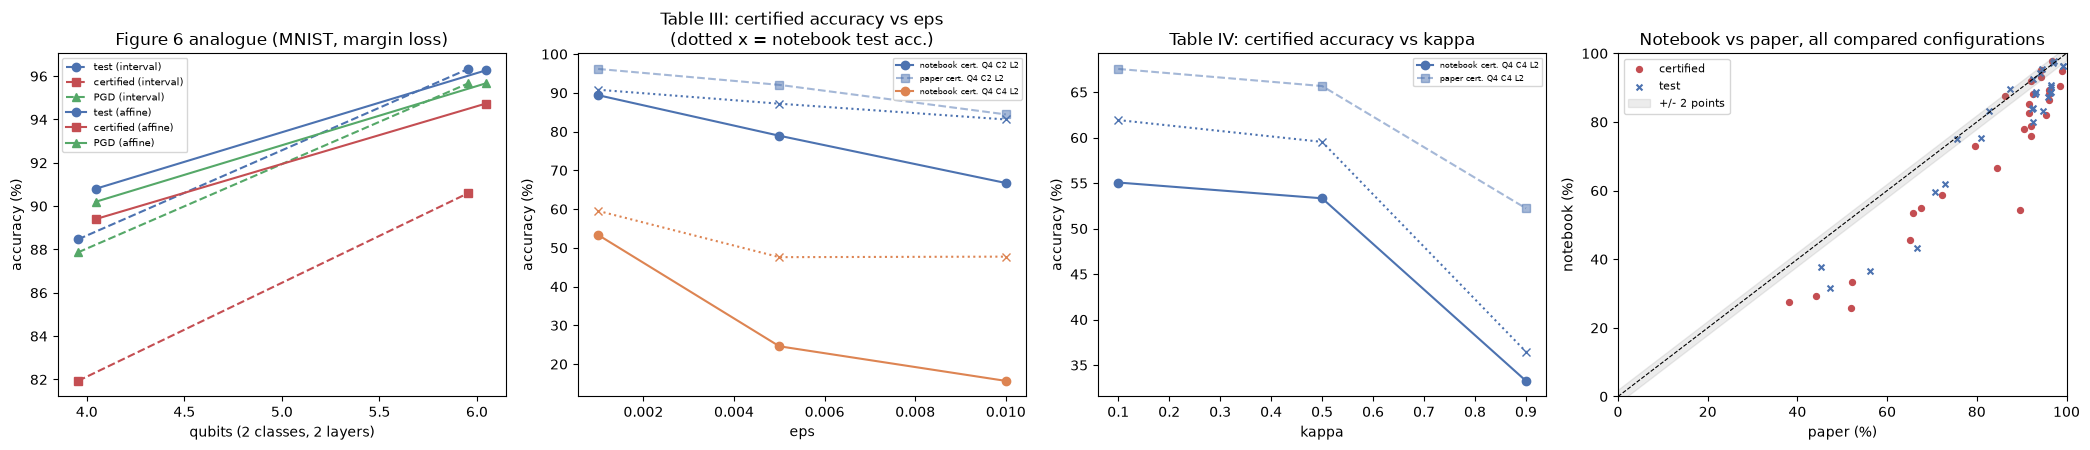

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.6))
# (1) Figure 6 analogue: MNIST, 2 classes, 2 layers, margin, both arithmetics
for k, arith in enumerate(("interval", "affine")):
    d = df[(df.ds == "MNIST") & (df.C == 2) & (df.L == 2) & (df.loss == "margin") & (df.arith == arith) & (df.kappa == KAPPA_DEFAULT) & (df.eps == EPS_DEFAULT) & (df.seed == 0)].sort_values("Q")
    off = (k - 0.5) * 0.9
    for m, (col, mk, nm) in enumerate((("test_acc", "o", "test"), ("cert_acc", "s", "certified"), ("pgd_acc", "^", "PGD"))):
        ax[0].plot(d["Q"] + off * 0.1, d[col], mk + ("-" if arith == "affine" else "--"), color=["#4c72b0", "#c44e52", "#55a868"][m], label=f"{nm} ({arith})")
ax[0].set_xlabel("qubits (2 classes, 2 layers)"); ax[0].set_ylabel("accuracy (%)"); ax[0].set_title("Figure 6 analogue (MNIST, margin loss)"); ax[0].legend(fontsize=7)

# (2) epsilon sweep, Table III
for (Q, C, L), col in (((4, 2, 2), "#4c72b0"), ((4, 2, 8), "#55a868"), ((4, 4, 2), "#dd8452")):
    d = df[(df.ds == "MNIST") & (df.Q == Q) & (df.C == C) & (df.L == L) & (df.arith == "affine") & (df.loss == "margin") & (df.kappa == KAPPA_DEFAULT) & (df.seed == 0)].sort_values("eps")
    if len(d) < 2: continue
    ax[1].plot(d["eps"], d["cert_acc"], "o-", color=col, label=f"notebook cert. Q{Q} C{C} L{L}")
    ax[1].plot(d["eps"], d["test_acc"], "x:", color=col)
    pe = [(e, PAPER_T3.get((Q, C, L, e))) for e in (0.001, 0.005, 0.010)]
    pe = [(e, v) for e, v in pe if v]
    if pe: ax[1].plot([e for e, _ in pe], [v[1] for _, v in pe], "s--", color=col, alpha=0.5, label=f"paper cert. Q{Q} C{C} L{L}")
ax[1].set_xlabel("eps"); ax[1].set_ylabel("accuracy (%)"); ax[1].set_title("Table III: certified accuracy vs eps\n(dotted x = notebook test acc.)"); ax[1].legend(fontsize=6)

# (3) kappa sweep, Table IV
for (Q, C, L), col in (((4, 4, 2), "#4c72b0"), ((6, 2, 2), "#55a868")):
    d = df[(df.ds == "MNIST") & (df.Q == Q) & (df.C == C) & (df.L == L) & (df.arith == "affine") & (df.loss == "margin") & (df.eps == EPS_DEFAULT) & (df.kappa < 1.0) & (df.seed == 0)].sort_values("kappa")
    if len(d) < 2: continue
    ax[2].plot(d["kappa"], d["cert_acc"], "o-", color=col, label=f"notebook cert. Q{Q} C{C} L{L}")
    ax[2].plot(d["kappa"], d["test_acc"], "x:", color=col)
    pk = [(k, PAPER_T4.get((Q, C, L, k))) for k in (0.1, 0.5, 0.9)]
    ax[2].plot([k for k, _ in pk], [v[1] for _, v in pk], "s--", color=col, alpha=0.5, label=f"paper cert. Q{Q} C{C} L{L}")
ax[2].set_xlabel("kappa"); ax[2].set_ylabel("accuracy (%)"); ax[2].set_title("Table IV: certified accuracy vs kappa"); ax[2].legend(fontsize=6)

# (4) notebook vs paper, every compared configuration
ax[3].scatter(cmp["paper_cert"], cmp["nb_cert"], s=18, c="#c44e52", label="certified")
ax[3].scatter(cmp["paper_acc"], cmp["nb_acc"], s=18, c="#4c72b0", marker="x", label="test")
ax[3].plot([0, 100], [0, 100], "k--", lw=0.8); ax[3].fill_between([0, 100], [-2, 98], [2, 102], color="grey", alpha=0.15, label="+/- 2 points")
ax[3].set_xlabel("paper (%)"); ax[3].set_ylabel("notebook (%)"); ax[3].set_xlim(0, 100); ax[3].set_ylim(0, 100); ax[3].legend(fontsize=8)
ax[3].set_title("Notebook vs paper, all compared configurations")
plt.tight_layout(); plt.show()

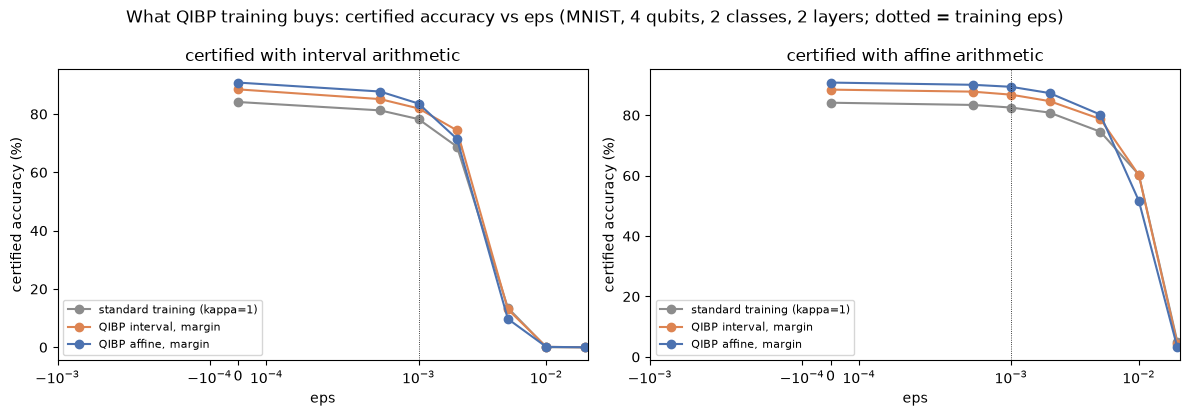

In [18]:
# Certified accuracy as a function of eps for models trained in three ways (MNIST, 4 qubits, 2 classes, 2 layers),
# each evaluated with BOTH bound-propagation methods. Extra figure, not in the paper.
def find(**kw):
    m = (df.ds == "MNIST") & (df.Q == 4) & (df.C == 2) & (df.L == 2) & (df.seed == 0)
    for k, v in kw.items(): m &= (df[k] == v)
    i = df[m].index
    return None if len(i) == 0 else RUNS[i[0]]
models = {"standard training (kappa=1)": find(kappa=1.0), "QIBP interval, margin": find(arith="interval", loss="margin", kappa=0.5, eps=EPS_DEFAULT),
          "QIBP affine, margin": find(arith="affine", loss="margin", kappa=0.5, eps=EPS_DEFAULT)}
Xte, yte = get_split("MNIST", 4, 2)[2:]
circ = Circuit(4, 2)
eps_grid = [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for j, method in enumerate(("interval", "affine")):
    for (nm, s), col in zip(models.items(), ("#8c8c8c", "#dd8452", "#4c72b0")):
        if s is None: continue
        th = THETAS[spec_key(s)]
        cert = [float((margin_of(*bounds(circ, Xte, th, e, 2, method), yte) > 0).double().mean()) * 100 for e in eps_grid]
        ax[j].plot(eps_grid, cert, "o-", color=col, label=nm)
    ax[j].axvline(EPS_DEFAULT, color="k", lw=0.6, ls=":")
    ax[j].set_xscale("symlog", linthresh=5e-4); ax[j].set_xlabel("eps"); ax[j].set_ylabel("certified accuracy (%)")
    ax[j].set_title(f"certified with {method} arithmetic"); ax[j].legend(fontsize=8)
plt.suptitle("What QIBP training buys: certified accuracy vs eps (MNIST, 4 qubits, 2 classes, 2 layers; dotted = training eps)")
plt.tight_layout(); plt.show()

In [19]:
# Classical baselines on exactly the same amplitude vectors (extra, not in the paper): test accuracy only, no certificate.
base = []
for (ds, Q, C) in (("MNIST", 4, 2), ("MNIST", 4, 4), ("MNIST", 6, 2), ("FMNIST", 4, 2), ("KMNIST", 4, 2)):
    Xtr, ytr, Xte, yte = get_split(ds, Q, C)
    row = dict(ds=ds, Q=Q, C=C)
    for nm, clf in (("LogReg", LogisticRegression(max_iter=2000, C=10.0, random_state=SEED)), ("SVC-rbf", SVC(kernel="rbf", C=10.0, gamma="scale", random_state=SEED)),
                    ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1))):
        clf.fit(Xtr.numpy(), ytr.numpy()); row[nm] = round(100 * clf.score(Xte.numpy(), yte.numpy()), 2)
    q = df[(df.ds == ds) & (df.Q == Q) & (df.C == C) & (df.L == 2) & (df.arith == "affine") & (df.loss == "margin") & (df.kappa == KAPPA_DEFAULT) & (df.eps == EPS_DEFAULT) & (df.seed == 0)]
    s = df[(df.ds == ds) & (df.Q == Q) & (df.C == C) & (df.L == 2) & (df.kappa == 1.0)]
    row["VQC standard (L=2)"] = round(float(s["test_acc"].iloc[0]), 2) if len(s) else np.nan
    row["VQC QIBP affine (L=2)"] = round(float(q["test_acc"].iloc[0]), 2) if len(q) else np.nan
    base.append(row)
print("Test accuracy (%) of classical models and of the 2-layer VQC on identical inputs:")
pd.DataFrame(base)

Test accuracy (%) of classical models and of the 2-layer VQC on identical inputs:


,ds,Q,C,LogReg,SVC-rbf,RandomForest,VQC standard (L=2),VQC QIBP affine (L=2)
0,MNIST,4,2,99.40,99.73,99.73,84.13,90.80
1,MNIST,4,4,92.93,96.53,96.20,31.67,59.53
2,MNIST,6,2,99.87,99.87,99.93,NaN,96.27
3,FMNIST,4,2,95.27,96.80,96.53,NaN,80.07
4,KMNIST,4,2,97.20,98.20,97.67,NaN,88.60


## 7. Verdict per claim of the paper

Each claim is tested with the notebook's own numbers by explicit rules (printed below). "Reproduced" means that the qualitative statement holds in this reduced replication; the numeric comparison with the tables is in section 6.

In [20]:
claims = []
def add(claim, status, evidence):
    claims.append(dict(claim=claim, verdict=status, evidence=evidence))
def sel(**kw):
    m = pd.Series(True, index=df.index)
    for k, v in kw.items(): m &= (df[k] == v)
    return df[m]
main = df[(df.kappa == KAPPA_DEFAULT) & (df.eps == EPS_DEFAULT) & (df.seed == 0)]

# C1 small model: certified accuracy close to test accuracy (paper: gap 0.99 points interval, 0.33 affine; MNIST 4q 2c 2L margin)
d = main[(main.ds == "MNIST") & (main.Q == 4) & (main.C == 2) & (main.L == 2) & (main.loss == "margin")]
if len(d) == 2:
    g = {a: float(d[d.arith == a].test_acc.iloc[0] - d[d.arith == a].cert_acc.iloc[0]) for a in ("interval", "affine")}
    add("C1 small VQC is certified almost up to its test accuracy (paper: gap 0.99 / 0.33 points, interval / affine)",
        "reproduced" if max(g.values()) <= 3.0 else "not reached", f"gap test-cert: interval {g['interval']:.2f}, affine {g['affine']:.2f} points (threshold 3)")
else: add("C1", "cannot be checked", "configuration missing")

# C2 soundness and ordering certified <= PGD <= test
ok_sound = (df.cert_but_fooled == 0).all()
ok_order = ((df.cert_acc <= df.pgd_acc + 1e-9) & (df.pgd_acc <= df.test_acc + 0.5)).mean()
add("C2 certified <= PGD <= test accuracy, and no certified sample is fooled by PGD", "reproduced" if ok_sound and ok_order > 0.95 else "not reached",
    f"certified-but-fooled samples: {int(df.cert_but_fooled.sum())}; fraction of models with cert <= PGD <= test: {ok_order:.2f}")

# C3 affine tighter than interval (same training recipe, certified accuracy, paired)
pairs = []
for _, r in main[main.arith == "affine"].iterrows():
    o = main[(main.ds == r.ds) & (main.Q == r.Q) & (main.C == r.C) & (main.L == r.L) & (main.loss == r.loss) & (main.arith == "interval")]
    if len(o): pairs.append((float(r.cert_acc), float(o.cert_acc.iloc[0]), float(r.test_acc - r.cert_acc), float(o.test_acc.iloc[0] - o.cert_acc.iloc[0])))
if pairs:
    P = np.array(pairs)
    add("C3 affine arithmetic gives higher certified accuracy / smaller test-cert gap than interval arithmetic", "reproduced" if (P[:, 0] >= P[:, 1] - 0.5).mean() >= 0.7 else "not reached",
        f"affine cert >= interval cert in {(P[:, 0] >= P[:, 1] - 0.5).sum()} of {len(P)} pairs; mean cert {P[:, 0].mean():.1f} vs {P[:, 1].mean():.1f}; mean gap {P[:, 2].mean():.1f} vs {P[:, 3].mean():.1f}")
else: add("C3", "cannot be checked", "no paired runs")

# C4 margin loss usually better than cross entropy
pairs = []
for _, r in main[main.loss == "margin"].iterrows():
    o = main[(main.ds == r.ds) & (main.Q == r.Q) & (main.C == r.C) & (main.L == r.L) & (main.loss == "ce") & (main.arith == r.arith)]
    if len(o): pairs.append((float(r.cert_acc), float(o.cert_acc.iloc[0])))
if pairs:
    P = np.array(pairs)
    add("C4 margin loss gives higher certified accuracy than cross entropy (typically)", "reproduced" if (P[:, 0] >= P[:, 1] - 0.5).mean() >= 0.6 else "not reached",
        f"margin >= CE in {(P[:, 0] >= P[:, 1] - 0.5).sum()} of {len(P)} pairs; mean cert {P[:, 0].mean():.1f} (margin) vs {P[:, 1].mean():.1f} (CE)")
else: add("C4", "cannot be checked", "no paired runs")

# C5 bigger eps lowers the certified accuracy, test accuracy stays similar (Table III)
res5 = []
for (Q, C, L) in ((4, 2, 2), (4, 2, 8), (4, 4, 2)):
    d = df[(df.ds == "MNIST") & (df.Q == Q) & (df.C == C) & (df.L == L) & (df.arith == "affine") & (df.loss == "margin") & (df.kappa == KAPPA_DEFAULT) & (df.seed == 0)].sort_values("eps")
    if len(d) >= 3: res5.append((Q, C, L, float(d.cert_acc.iloc[0] - d.cert_acc.iloc[-1]), float(abs(d.test_acc.iloc[0] - d.test_acc.iloc[-1]))))
if res5:
    add("C5 larger eps lowers certified accuracy while test accuracy stays similar", "reproduced" if all(a > 0 for *_, a, b in res5) and all(b < a + 5 for *_, a, b in res5) else "not reached",
        "; ".join(f"Q{Q}C{C}L{L}: cert drops {a:.1f} pts (eps 0.001 -> 0.010), test changes {b:.1f} pts" for Q, C, L, a, b in res5))
else: add("C5", "cannot be checked", "no eps sweep")

# C6 smaller kappa helps (0.9 -> 0.1), Table IV
res6 = []
for (Q, C, L) in ((4, 4, 2), (6, 2, 2)):
    d = df[(df.ds == "MNIST") & (df.Q == Q) & (df.C == C) & (df.L == L) & (df.arith == "affine") & (df.loss == "margin") & (df.eps == EPS_DEFAULT) & (df.kappa < 1.0) & (df.seed == 0)].sort_values("kappa")
    if len(d) >= 3: res6.append((Q, C, L, float(d.cert_acc.iloc[0]), float(d.cert_acc.iloc[-1]), float(d.test_acc.iloc[0]), float(d.test_acc.iloc[-1])))
if res6:
    add("C6 smaller kappa (0.9 -> 0.1) improves certified and test accuracy (4 qubits)", "reproduced" if all(a >= b - 1.0 for _, _, _, a, b, _, _ in res6) else "not reached",
        "; ".join(f"Q{Q}C{C}L{L}: cert {b:.1f} (kappa 0.9) -> {a:.1f} (0.1), test {d:.1f} -> {c:.1f}" for Q, C, L, a, b, c, d in res6))
else: add("C6", "cannot be checked", "no kappa sweep")

# C7 more classes -> lower accuracy (same qubits, layers)
res7 = []
for (Q, L, loss, arith) in ((4, 2, "margin", "affine"), (4, 2, "margin", "interval"), (4, 8, "margin", "affine")):
    d = main[(main.ds == "MNIST") & (main.Q == Q) & (main.L == L) & (main.loss == loss) & (main.arith == arith)].sort_values("C")
    if len(d) >= 2: res7.append((Q, L, arith, float(d.test_acc.iloc[0]), float(d.test_acc.iloc[-1]), float(d.cert_acc.iloc[0]), float(d.cert_acc.iloc[-1])))
if res7:
    add("C7 more classes lower test and certified accuracy (paper: 98 -> 80 % at 4 qubits)", "reproduced" if all(a > b and c > d for _, _, _, a, b, c, d in res7) else "not reached",
        "; ".join(f"Q{Q} L{L} {ar}: test {a:.1f} -> {b:.1f}, cert {c:.1f} -> {d:.1f}" for Q, L, ar, a, b, c, d in res7))
else: add("C7", "cannot be checked", "no paired class counts")

# C8 QIBP training certifies much better than standard training (motivation of the paper; baseline added here)
res8 = []
for _, r in df[df.kappa == 1.0].iterrows():
    o = main[(main.ds == r.ds) & (main.Q == r.Q) & (main.C == r.C) & (main.L == r.L) & (main.loss == "margin") & (main.arith == "affine")]
    if len(o): res8.append((r.Q, r.C, r.L, float(r.cert_acc), float(o.cert_acc.iloc[0]), float(r.test_acc), float(o.test_acc.iloc[0])))
if res8:
    add("C8 (extra, implicit in the paper) QIBP training certifies more samples than standard training at the same eps", "reproduced" if np.mean([b >= a - 0.5 for _, _, _, a, b, _, _ in res8]) >= 0.5 else "not reached",
        "; ".join(f"Q{Q}C{C}L{L}: cert {a:.1f} (standard) vs {b:.1f} (QIBP), test {c:.1f} vs {d:.1f}" for Q, C, L, a, b, c, d in res8))
else: add("C8", "cannot be checked", "no standard-training runs")

# C9 numbers within 2 points of the paper
add("C9 absolute numbers of Tables I to IV", "reproduced" if (cmp.verdict_cert == "reproduced").mean() >= 0.8 else ("partly" if (cmp.verdict_cert == "reproduced").mean() > 0 else "not reached"),
    f"certified accuracy within 2 points in {(cmp.verdict_cert == 'reproduced').sum()} of {len(cmp)} comparisons; test accuracy in {(cmp.verdict_acc == 'reproduced').sum()} of {len(cmp)} (reduced training budget)")
add("C10 8- and 10-qubit models and the full paper grid", "cannot be checked", "8- and 10-qubit models were not run within the CPU budget of this execution (extend run_specs to include them)")

claims = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 220)
for _, r in claims.iterrows():
    print(f"[{r.verdict.upper():18s}] {r.claim}\n{'':21s}evidence: {r.evidence}\n")

[NOT REACHED       ] C1 small VQC is certified almost up to its test accuracy (paper: gap 0.99 / 0.33 points, interval / affine)
                     evidence: gap test-cert: interval 6.53, affine 1.40 points (threshold 3)

[REPRODUCED        ] C2 certified <= PGD <= test accuracy, and no certified sample is fooled by PGD
                     evidence: certified-but-fooled samples: 0; fraction of models with cert <= PGD <= test: 1.00

[REPRODUCED        ] C3 affine arithmetic gives higher certified accuracy / smaller test-cert gap than interval arithmetic
                     evidence: affine cert >= interval cert in 11 of 11 pairs; mean cert 78.8 vs 66.7; mean gap 2.0 vs 13.4

[REPRODUCED        ] C4 margin loss gives higher certified accuracy than cross entropy (typically)
                     evidence: margin >= CE in 7 of 8 pairs; mean cert 73.5 (margin) vs 65.4 (CE)

[REPRODUCED        ] C5 larger eps lowers certified accuracy while test accuracy stays similar
                    

In [21]:
# Spread over seeds for one configuration (MNIST, 4 qubits, 2 classes, 2 layers, affine, margin)
sd = df[(df.ds == "MNIST") & (df.Q == 4) & (df.C == 2) & (df.L == 2) & (df.arith == "affine") & (df.loss == "margin") & (df.kappa == KAPPA_DEFAULT) & (df.eps == EPS_DEFAULT)]
print(f"{len(sd)} seed(s): test {sd.test_acc.mean():.2f} +/- {sd.test_acc.std(ddof=0):.2f}, certified {sd.cert_acc.mean():.2f} +/- {sd.cert_acc.std(ddof=0):.2f}, PGD {sd.pgd_acc.mean():.2f} +/- {sd.pgd_acc.std(ddof=0):.2f} (paper: 96.50 / 96.17 / 96.22)")
print("sum of the training+evaluation times of all %d models: %.1f min (models found in the cache of an earlier, interrupted run are included; wall-clock of this session: %.1f min)" % (len(df), df["train_time"].sum() / 60, (time.time() - T0) / 60))

3 seed(s): test 89.87 +/- 0.86, certified 87.93 +/- 1.26, PGD 89.07 +/- 0.95 (paper: 96.50 / 96.17 / 96.22)
sum of the training+evaluation times of all 32 models: 48.4 min (models found in the cache of an earlier, interrupted run are included; wall-clock of this session: 1.6 min)


## Reading the paper critically

* **What the guarantee means.** A certified sample is guaranteed correct for every perturbation of the *normalised amplitude vector* inside an `l_inf` ball of radius `eps`. With `eps = 0.001` and a 16-dimensional amplitude vector (4 qubits) the ball is tiny compared with the amplitudes (about 0.25 each), but for 10 qubits (1024 amplitudes of size about 0.03) the same `eps` is a much larger *relative* perturbation. Part of the paper's observation that "larger models certify worse" is therefore an effect of the fixed absolute `eps`, not necessarily of depth or size alone. Perturbations of the raw pixels and the normalisation step are not covered by the certificate.
* **Complex arithmetic is not needed.** `RY` and `CNOT` are real, so the paper's real and imaginary intervals reduce to a real box; the imaginary part is identically zero. The interesting part is only the dependency problem of the box versus the exact linear image.
* **Where interval arithmetic loses.** The box is propagated layer by layer (as in classical IBP), so every layer multiplies the width by roughly `sum_k |K_jk|`. The affine version propagates the exact linear image (the product matrix `U`) and only loses precision in the squaring step. This notebook implements the affine squaring with one residual per amplitude (Eq. 22); a tighter bound on the quadratic form would be possible and would help further.
* **PGD is a weak upper bound.** The paper uses PGD accuracy as an "upper bound" for certified accuracy. It is an upper bound for the certifiable region only if the attack is optimal; the gap between PGD and certified accuracy is what is left to improve, but a stronger attack could lower the PGD accuracy.
* **Small-data caveat of this notebook.** Training sets of 2 000 to 5 000 images and a few thousand optimiser steps are used instead of the full data set. Test accuracies of the larger models are therefore lower than the paper's; relative trends (affine versus interval, margin versus cross entropy, effect of `eps` and `kappa`) are the meaningful outputs. A single seed per configuration is noisy (see the seed-spread cell), so differences of one or two points should not be over-read.
* **Unspecified details of the paper.** Batch size, weight initialisation, the exact CNOT wiring, the PGD settings and the handling of the `eps` schedule are not specified; each of them can change the absolute numbers. The paper also shows no standard-training baseline; the one in this notebook shows how much of the certified accuracy is due to QIBP training.
* **Not an attack-robustness claim for hardware.** The certificate is about the exact noiseless state vector; shot noise and hardware noise add to the logits and are not covered.

## Exercises

1. **Change the CNOT pattern.** Replace the brick-work in `entangler_pairs` by a ring or a single chain and compare test / certified accuracy for 4 qubits, 2 classes, 2 layers. Does the choice matter for the width of the bounds?
2. **Tighter squaring.** In `bounds_affine` the quadratic term is bounded per amplitude. Bound `sum_j (sum_k g_jk e_k)^2` jointly (it is a quadratic form in the noise symbols) and measure how much the certified accuracy of the same trained weights improves.
3. **Mixed arithmetic.** Train with interval arithmetic and certify with affine arithmetic (and the reverse). The extra figure only does this for three models; run it for the whole grid and report where the two certificates disagree most.
4. **Scaling the logits.** The logits are raw expectation values in [-1, 1], which makes the cross-entropy term weak for many classes. Multiply the logits by a temperature `T` (try 2, 5, 10) before the cross entropy and see whether the 4-class models improve.
5. **Closer to the paper's budget.** Set `N_TRAIN` to the full number of training images, `EPOCHS = 30` and `FAST_MODE = False`, run the 4-qubit models of Table II and report how the gap to the paper's numbers changes with the data size. Then add `Q = 8` and `Q = 10` for 2 classes and 2 layers (not in the grid executed here) and check the paper's 10-qubit claims.